# Scanpy: Differential expression

Once we have done clustering, let's compute a ranking for the highly differential genes in each cluster.


Differential expression is performed with the function `rank_genes_group`.  The default method to compute differential expression is the `t-test_overestim_var`. Other implemented methods are: `logreg`, `t-test` and `wilcoxon`.

By default, the .raw attribute of AnnData is used in case it has been initialized, it can be changed by setting `use_raw=False`.

The clustering with resolution 0.6 seems to give a reasonable number of clusters, so we will use that clustering for all DE tests.

First, let's import libraries and fetch the clustered data from the previous lab.

In [ ]:
import numpy as np
import pandas as pd
import scanpy as sc
import gseapy
import matplotlib.pyplot as plt

sc.settings.verbosity = 2             # verbosity: errors (0), warnings (1), info (2), hints (3)
#sc.logging.print_versions()


In [ ]:
sc.settings.set_figure_params(dpi=80)

Read in the clustered data object.

In [ ]:
adata = sc.read_h5ad('./data/results/scanpy_clustered_covid.h5ad')

In [ ]:
print(adata.X.shape)
print(adata.raw.X.shape)
print(adata.raw.X[:10,:10])

(5594, 3067)
(5594, 18752)
  (0, 1)	1.0
  (0, 6)	1.0
  (1, 6)	2.0
  (2, 6)	1.0


As you can see, the X matrix only contains the variable genes, while the raw matrix contains all genes.

Printing a few of the values in `adata.raw.X` shows that the raw matrix is not normalized.

For DGE analysis we would like to run with all genes, but on normalized values, so we will have to revert back to the raw matrix and renormalize.

In [ ]:
adata = adata.raw.to_adata()
sc.pp.normalize_per_cell(adata, counts_per_cell_after=1e4)
sc.pp.log1p(adata)


normalizing by total count per cell
    finished (0:00:00): normalized adata.X and added    'n_counts', counts per cell before normalization (adata.obs)


### T-test

ranking genes
    finished (0:00:01)


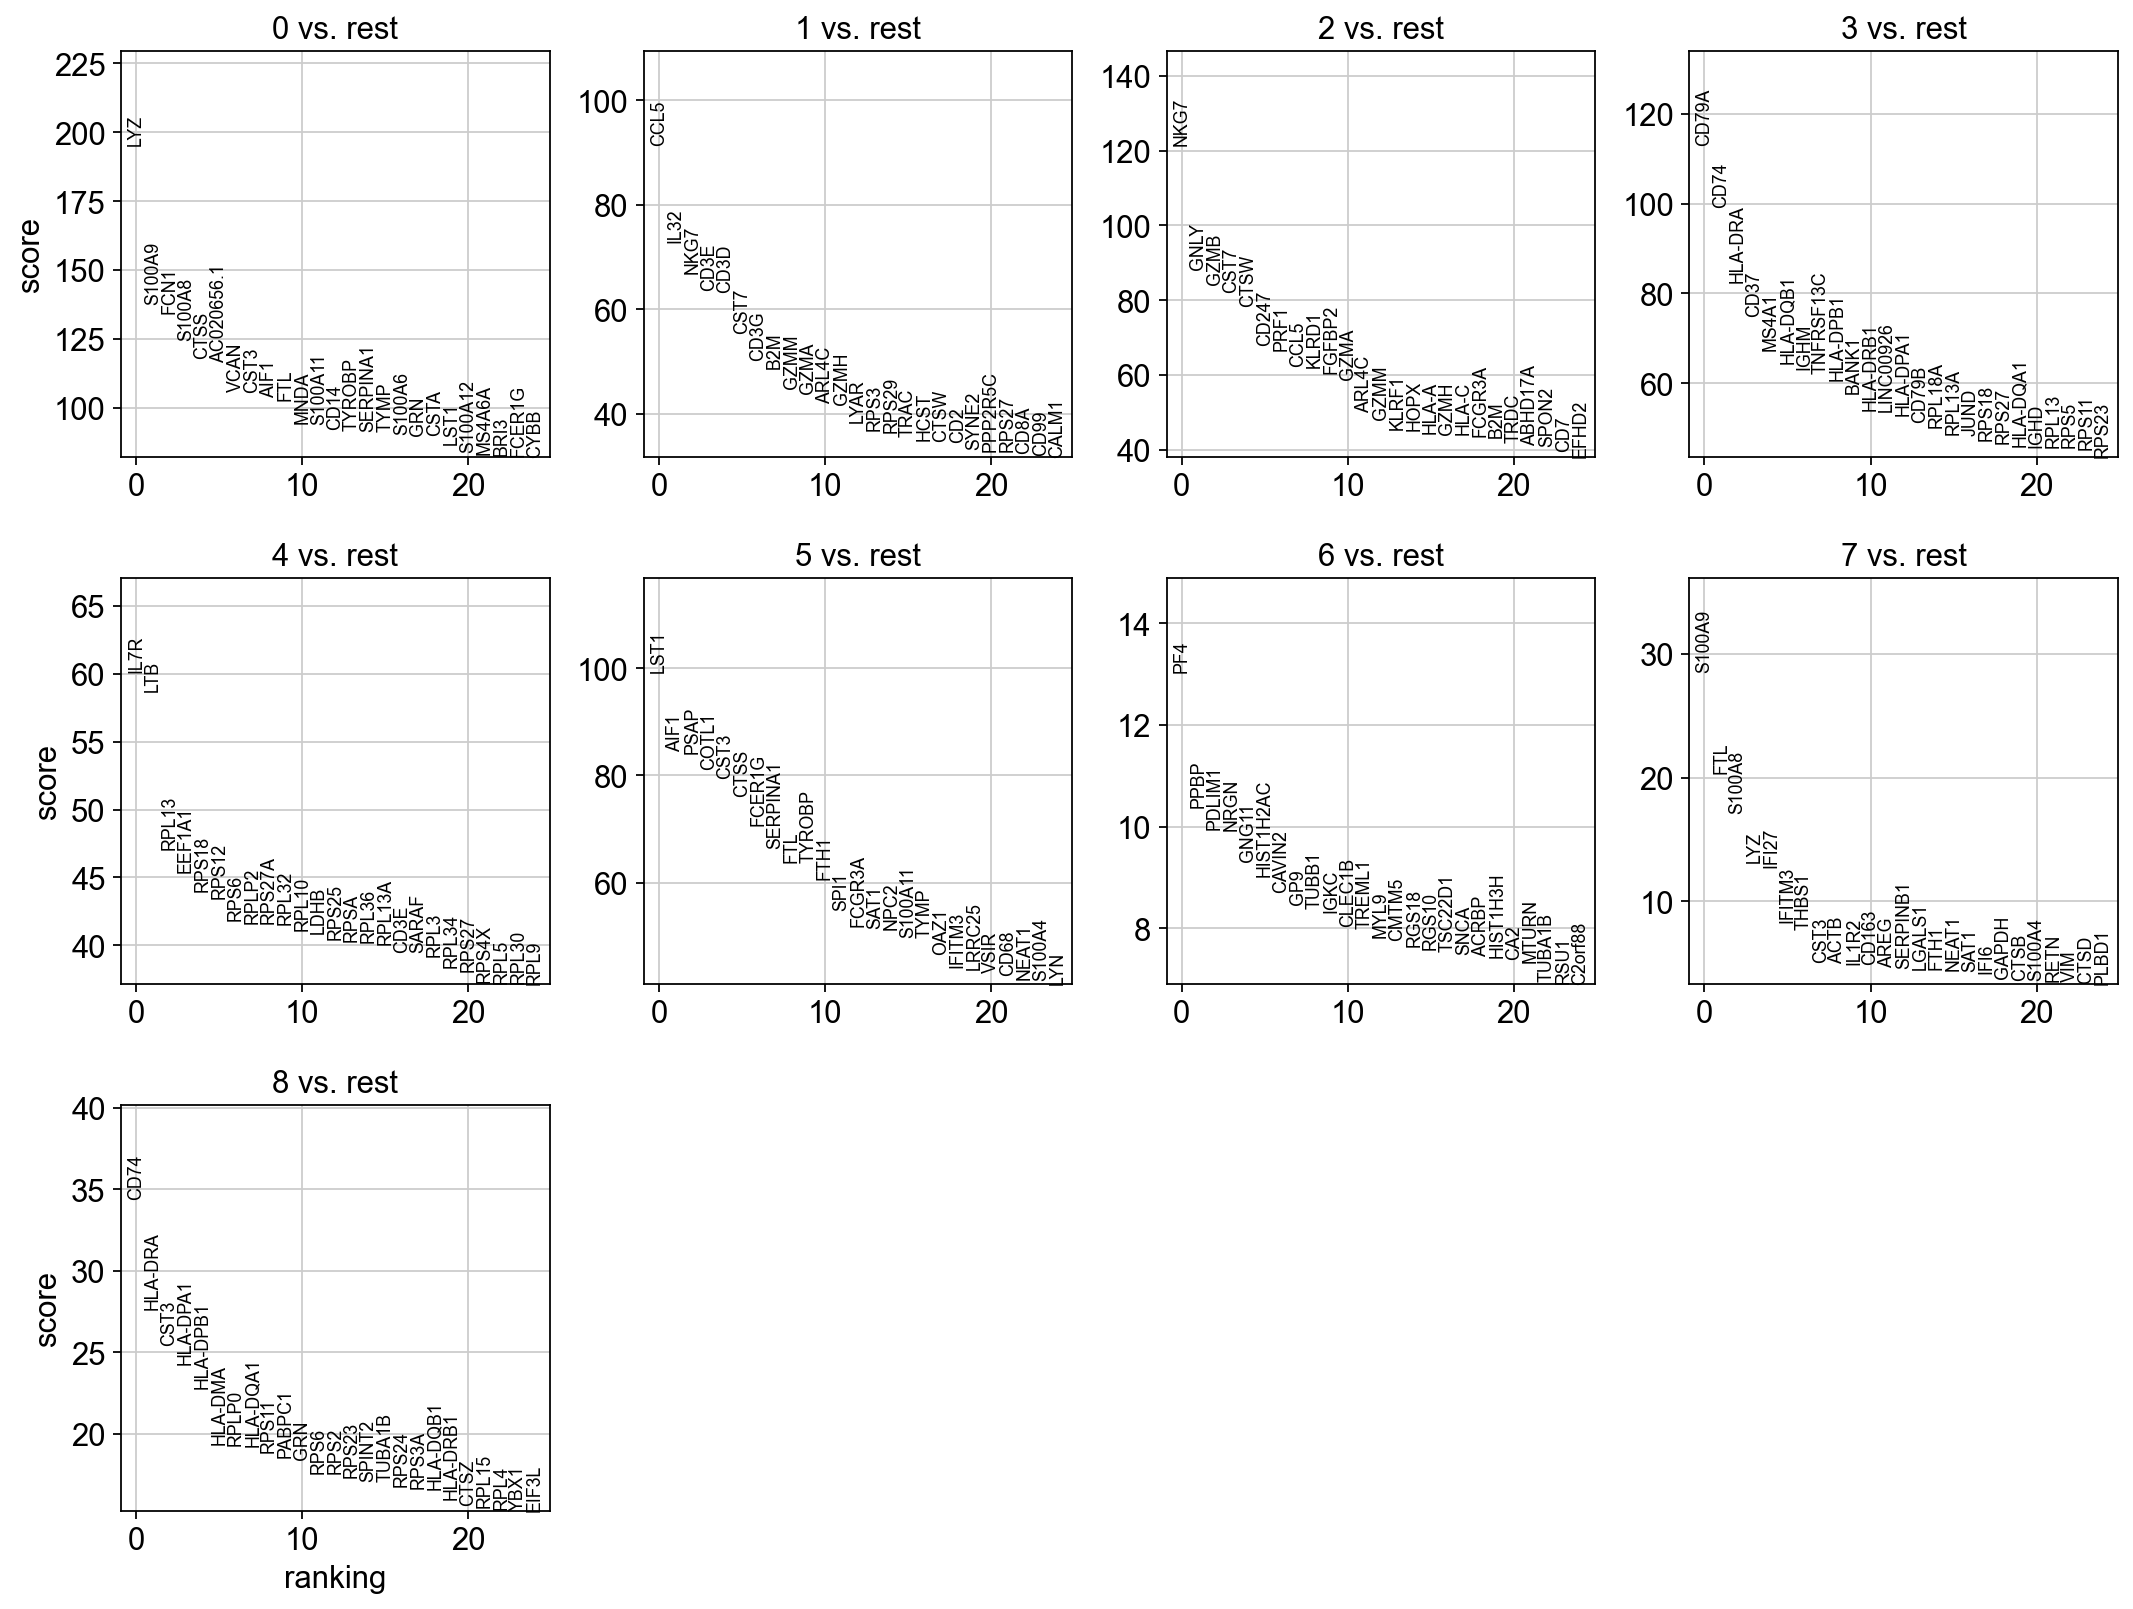

In [ ]:
sc.tl.rank_genes_groups(adata, 'louvain_0.6', method='t-test', key_added = "t-test")
sc.pl.rank_genes_groups(adata, n_genes=25, sharey=False, key = "t-test")


In [ ]:
# results are stored in the adata.uns["t-test"] slot
adata

AnnData object with n_obs × n_vars = 5594 × 18752
    obs: 'type', 'sample', 'batch', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'pct_counts_hb', 'percent_mt2', 'n_counts', 'n_genes', 'S_score', 'G2M_score', 'phase', 'doublet_scores', 'predicted_doublets', 'doublet_info', 'leiden_1.0', 'leiden_0.6', 'leiden_0.4', 'leiden_1.4', 'louvain_1.0', 'louvain_0.6', 'louvain_0.4', 'louvain_1.4', 'kmeans5', 'kmeans10', 'kmeans15', 'hclust_5', 'hclust_10', 'hclust_15'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells'
    uns: 'dendrogram_leiden_0.6', 'dendrogram_louvain_0.6', 'doublet_info_colors', 'hclust_10_colors', 'hclust_15_colors', 'hclust_5_colors', 'hvg', 'kmeans10_colors', 'kmeans15_colors', 'kmeans5_colors', 'leiden', 'leiden_0.4_colors', 'leiden_0.6_colors', 'leiden_1.0_colors', 'leiden_1.4_color

### T-test overestimated_variance

ranking genes
    finished (0:00:01)


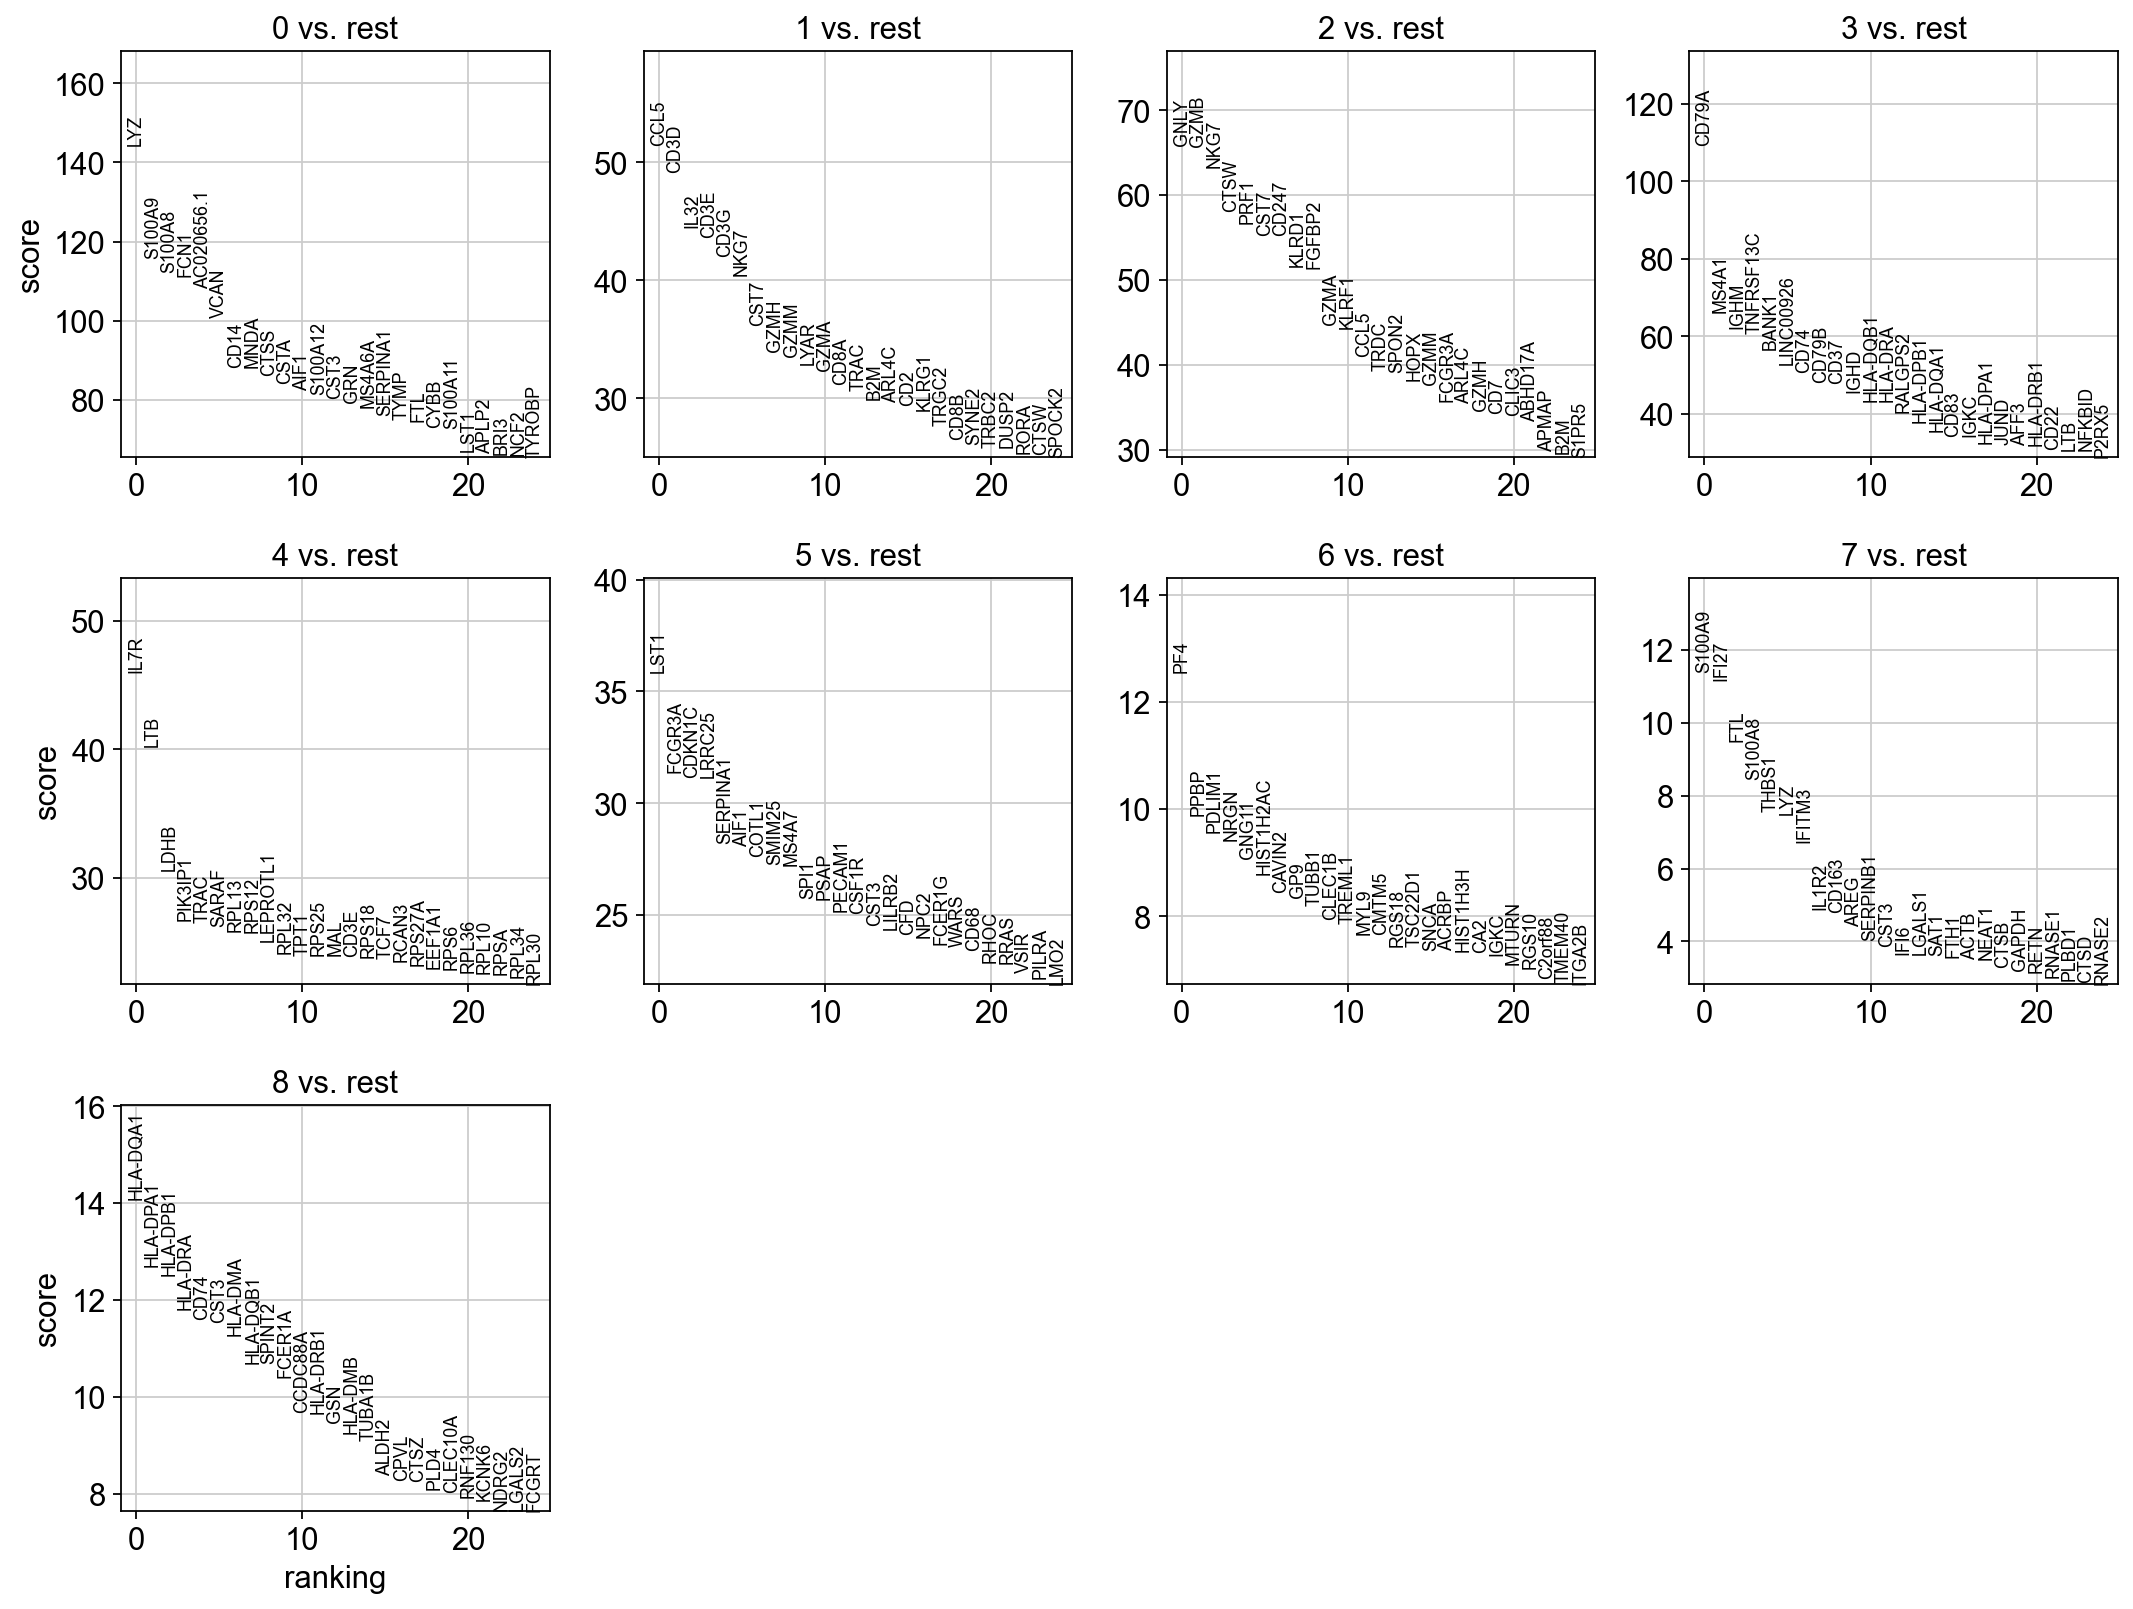

In [ ]:
sc.tl.rank_genes_groups(adata, 'louvain_0.6', method='t-test_overestim_var', key_added = "t-test_ov")
sc.pl.rank_genes_groups(adata, n_genes=25, sharey=False, key = "t-test_ov")


### Wilcoxon rank-sum

The result of a [Wilcoxon rank-sum (Mann-Whitney-U)](https://de.wikipedia.org/wiki/Wilcoxon-Mann-Whitney-Test) test is very similar. We recommend using the latter in publications, see e.g., [Sonison & Robinson (2018)](https://doi.org/10.1038/nmeth.4612). You might also consider much more powerful differential testing packages like MAST, limma, DESeq2 and, for python, the recent diffxpy.

ranking genes
    finished (0:00:08)


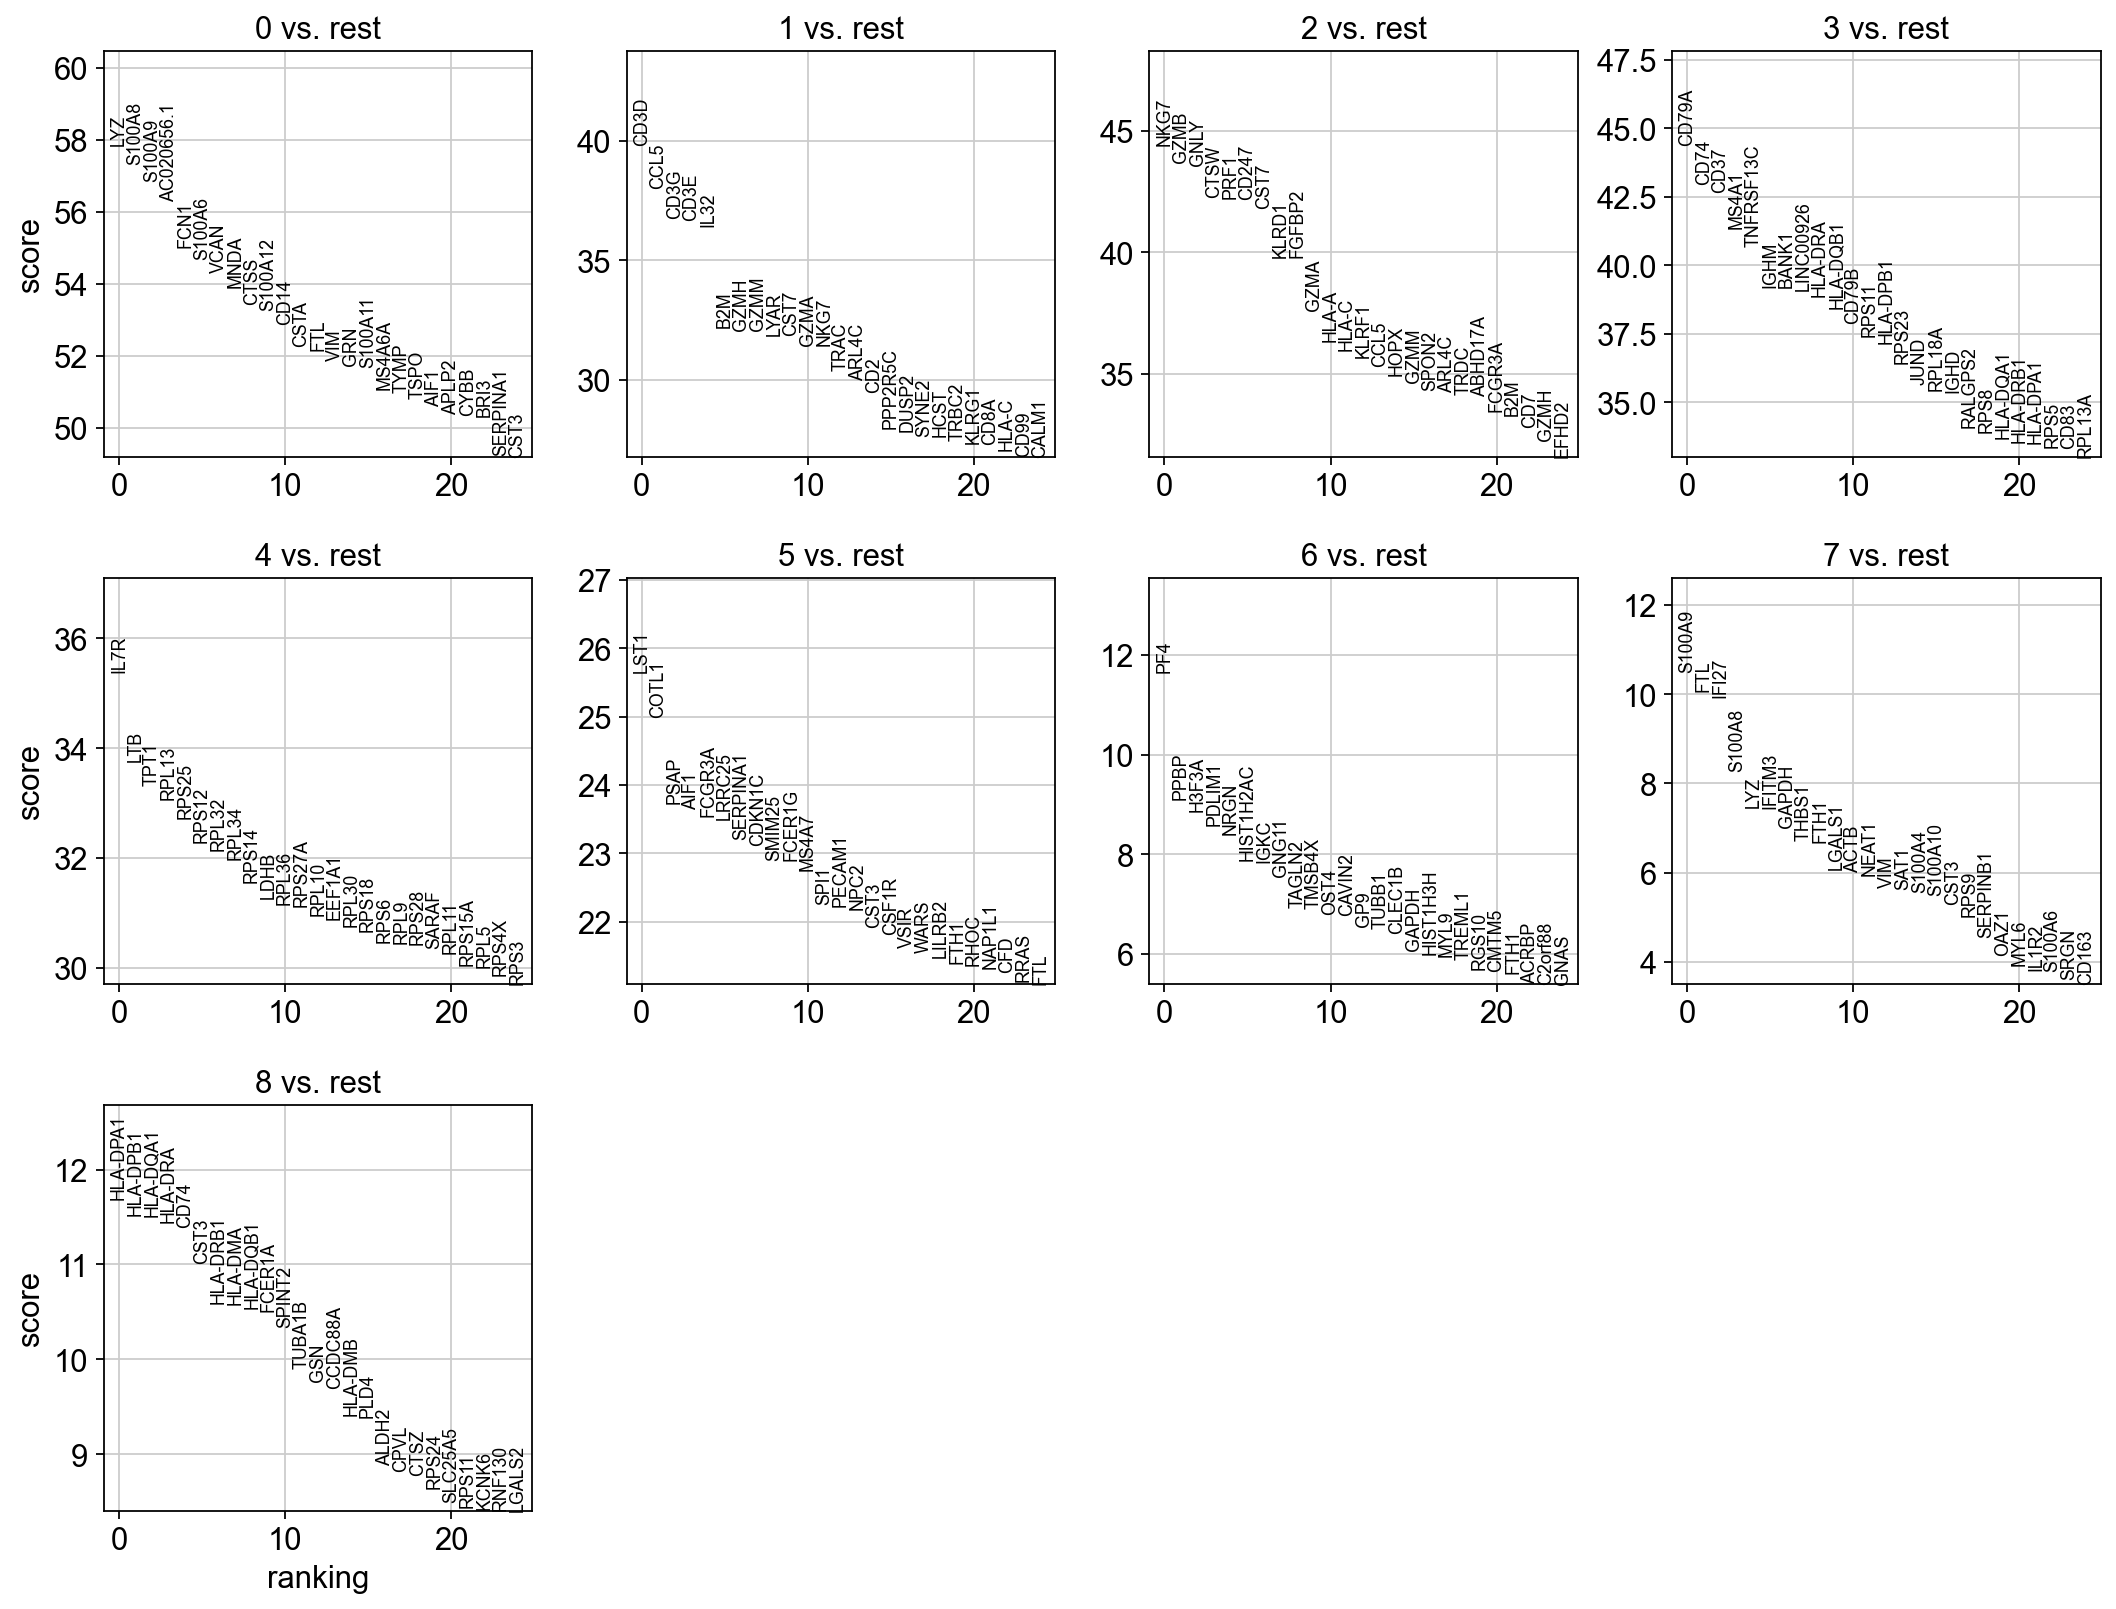

In [ ]:
sc.tl.rank_genes_groups(adata, 'louvain_0.6', method='wilcoxon', key_added = "wilcoxon")
sc.pl.rank_genes_groups(adata, n_genes=25, sharey=False, key="wilcoxon")

### Logistic regression test

As an alternative, let us rank genes using logistic regression. For instance, this has been suggested by [Natranos et al. (2018)](https://doi.org/10.1101/258566). The essential difference is that here, we use a multi-variate appraoch whereas conventional differential tests are uni-variate. [Clark et al. (2014)](https://doi.org/10.1186/1471-2105-15-79) has more details.

ranking genes
    finished (0:00:34)


/Users/asbj/miniconda3/envs/scRNAseq2022_tmp/lib/python3.9/site-packages/sklearn/linear_model/_logistic.py:814: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


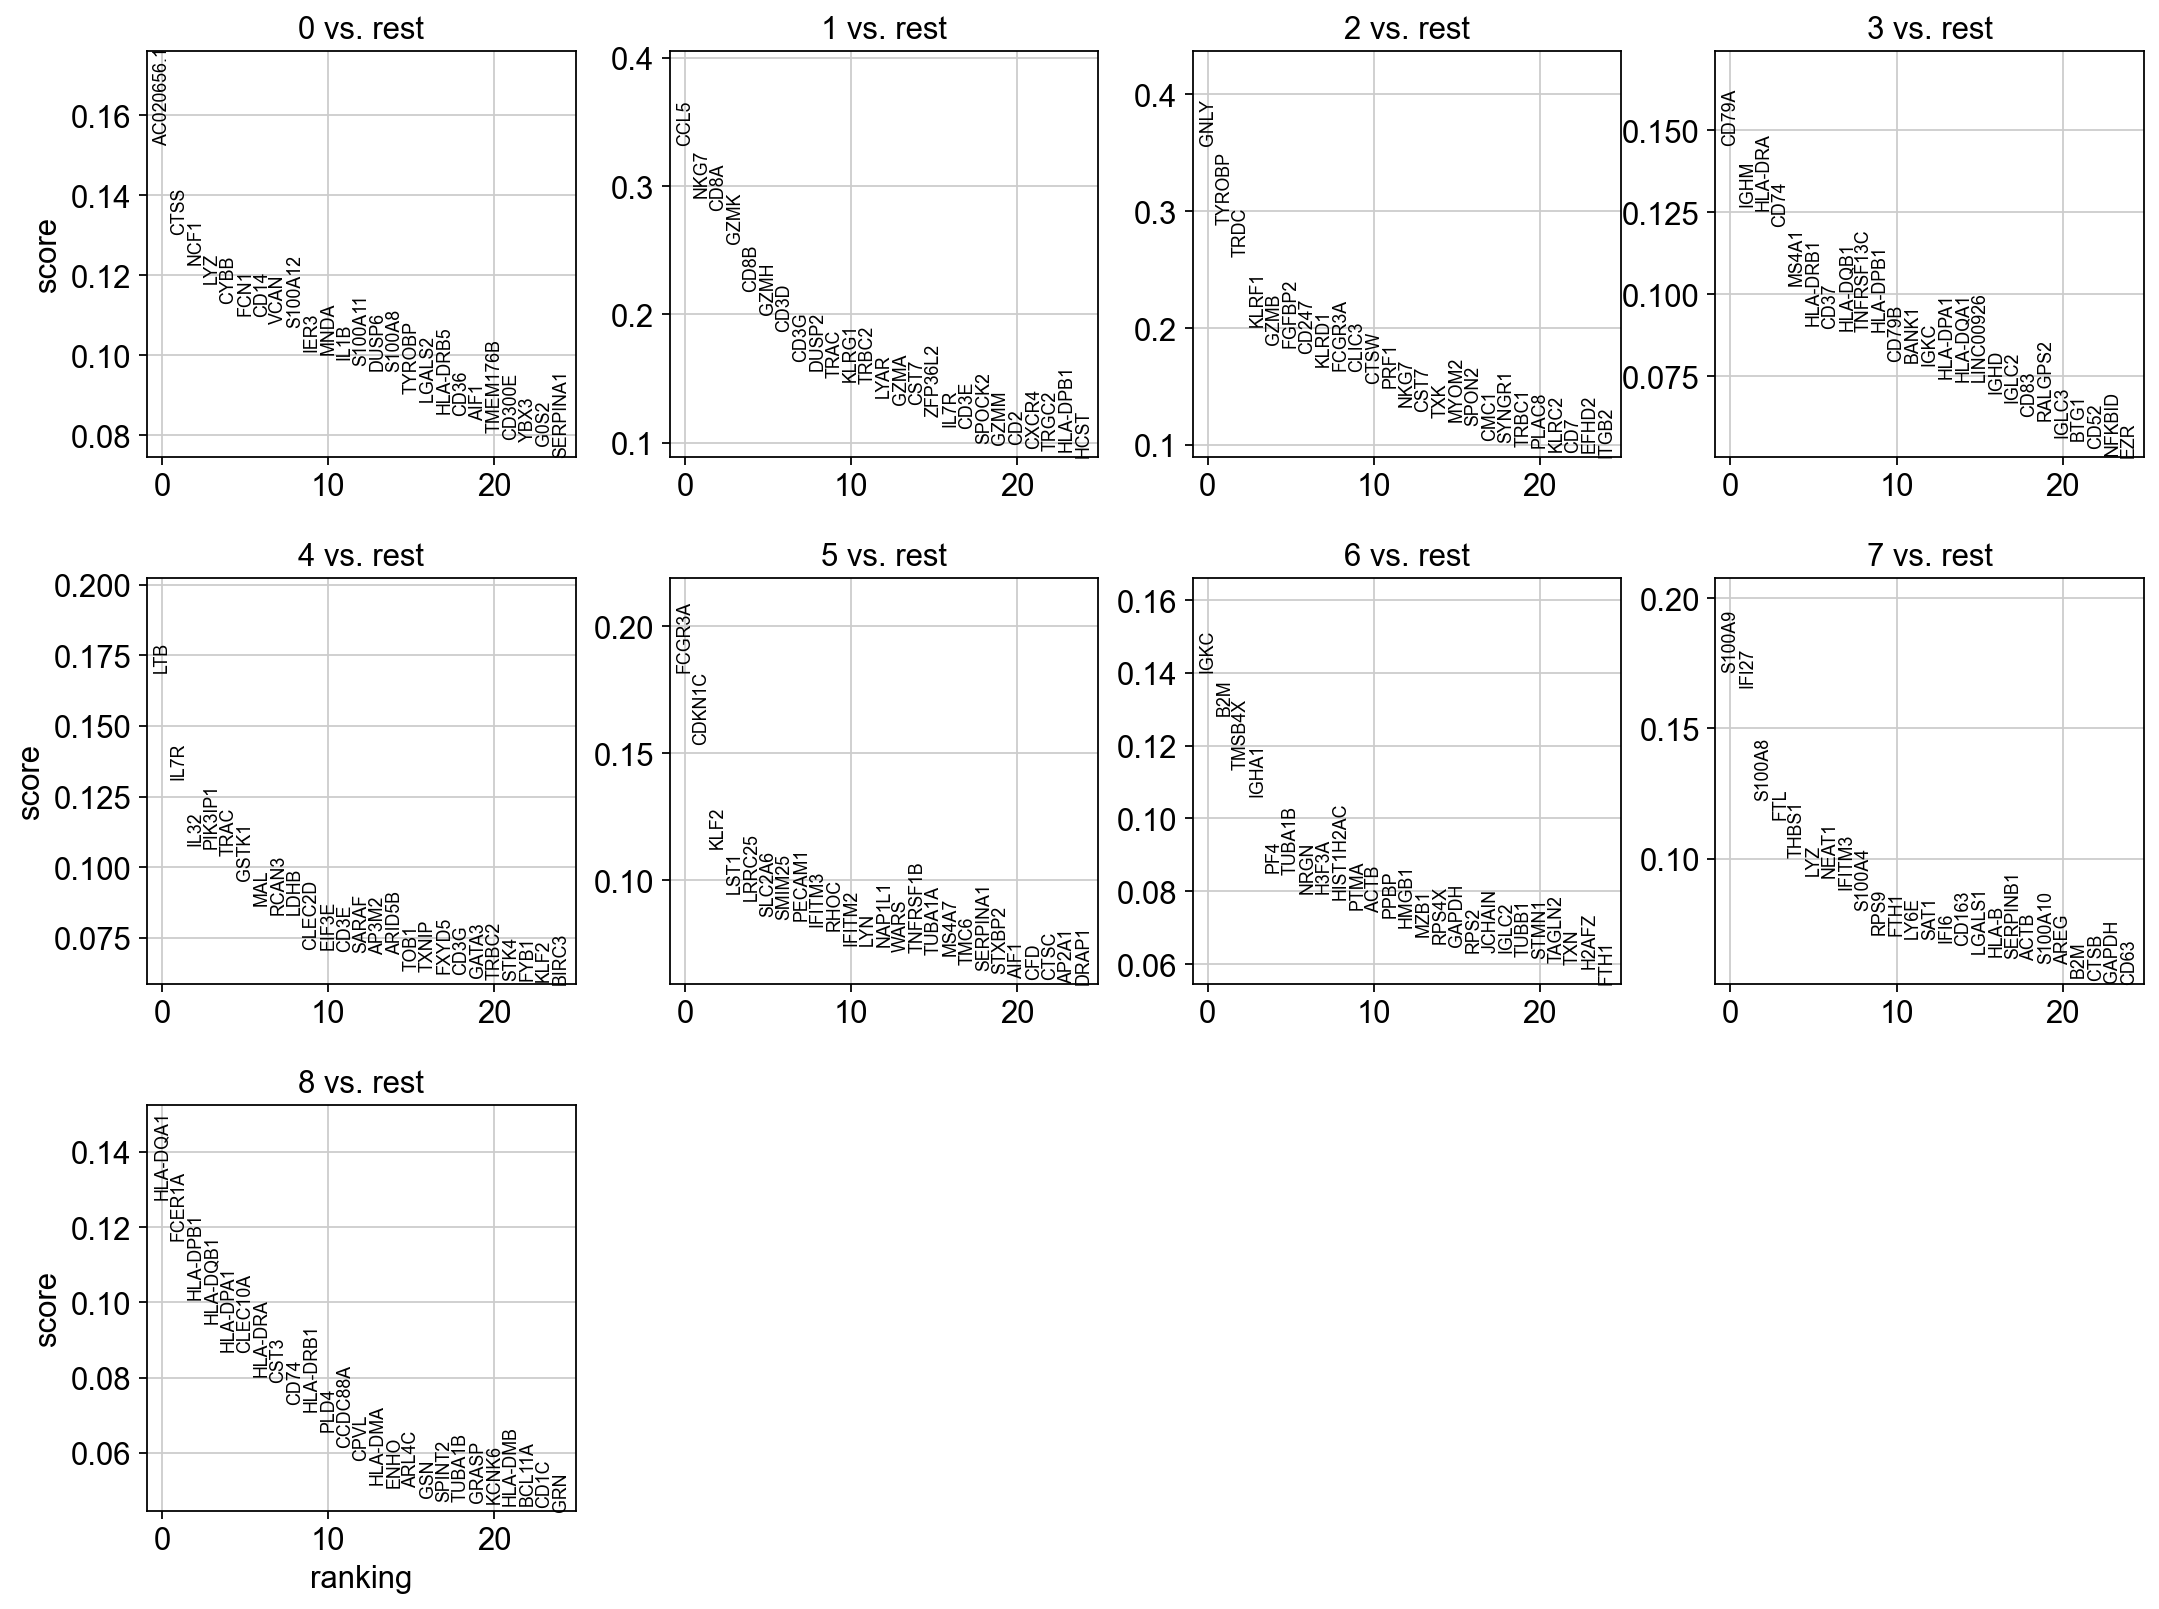

In [ ]:
sc.tl.rank_genes_groups(adata, 'louvain_0.6', method='logreg',key_added = "logreg")
sc.pl.rank_genes_groups(adata, n_genes=25, sharey=False, key = "logreg")

### Compare genes

Take all significant DE genes for cluster0 with each test and compare the overlap.

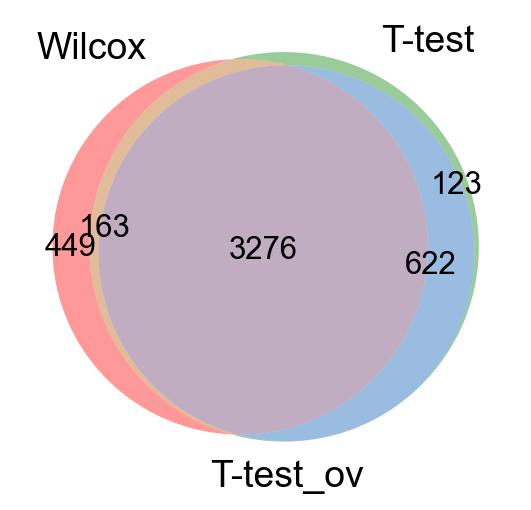

In [ ]:
#compare cluster1 genes, only stores top 100 by default

wc = sc.get.rank_genes_groups_df(adata, group='0', key='wilcoxon', pval_cutoff=0.01, log2fc_min=0)['names']
tt = sc.get.rank_genes_groups_df(adata, group='0', key='t-test', pval_cutoff=0.01, log2fc_min=0)['names']
tt_ov = sc.get.rank_genes_groups_df(adata, group='0', key='t-test_ov', pval_cutoff=0.01, log2fc_min=0)['names']

from matplotlib_venn import venn3

venn3([set(wc),set(tt),set(tt_ov)], ('Wilcox','T-test','T-test_ov') )
plt.show()



As you can see, the Wilcoxon test and the T-test with overestimated variance gives very similar result. Also the regular T-test has good overlap, while the Logistic regression gives quite different genes.

### Visualization

There are several ways to visualize the expression of top DE genes. Here we will plot top 5 genes per cluster from Wilcoxon test as heatmap, dotplot, violin plot or matrix.

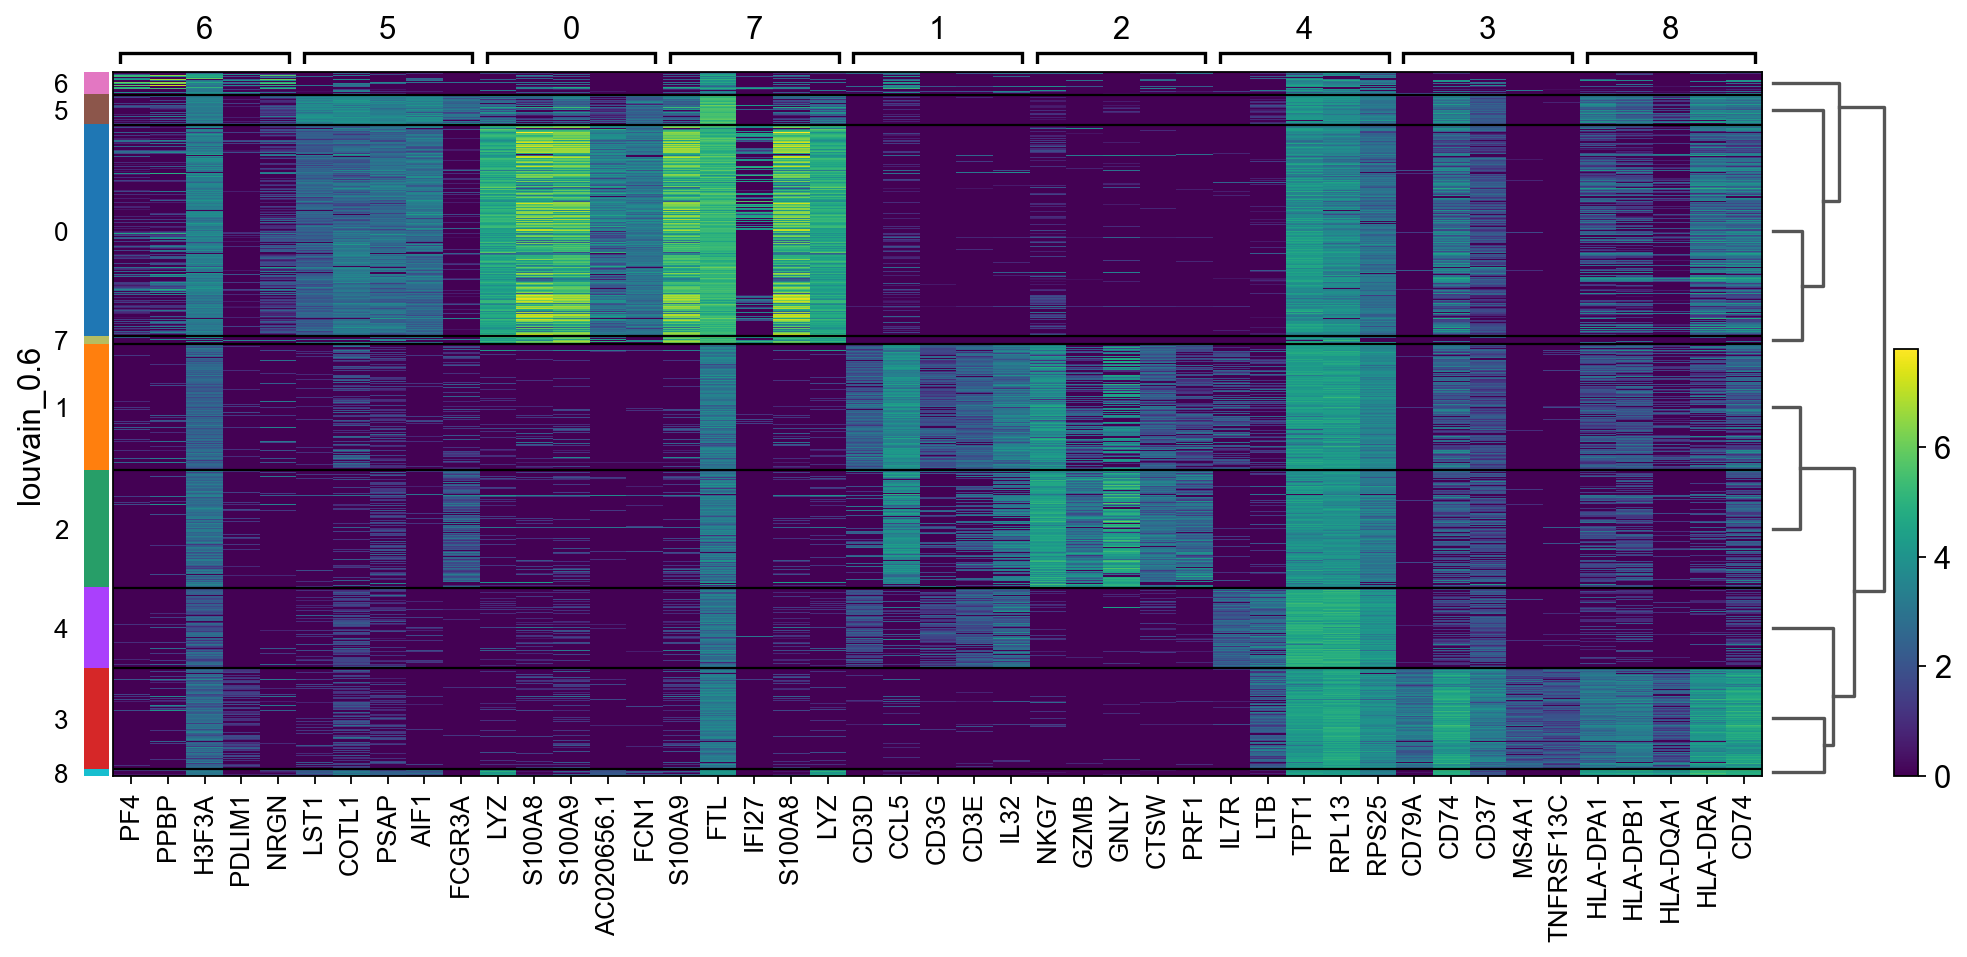

In [ ]:
sc.pl.rank_genes_groups_heatmap(adata, n_genes=5, key="wilcoxon", groupby="louvain_0.6", show_gene_labels=True)

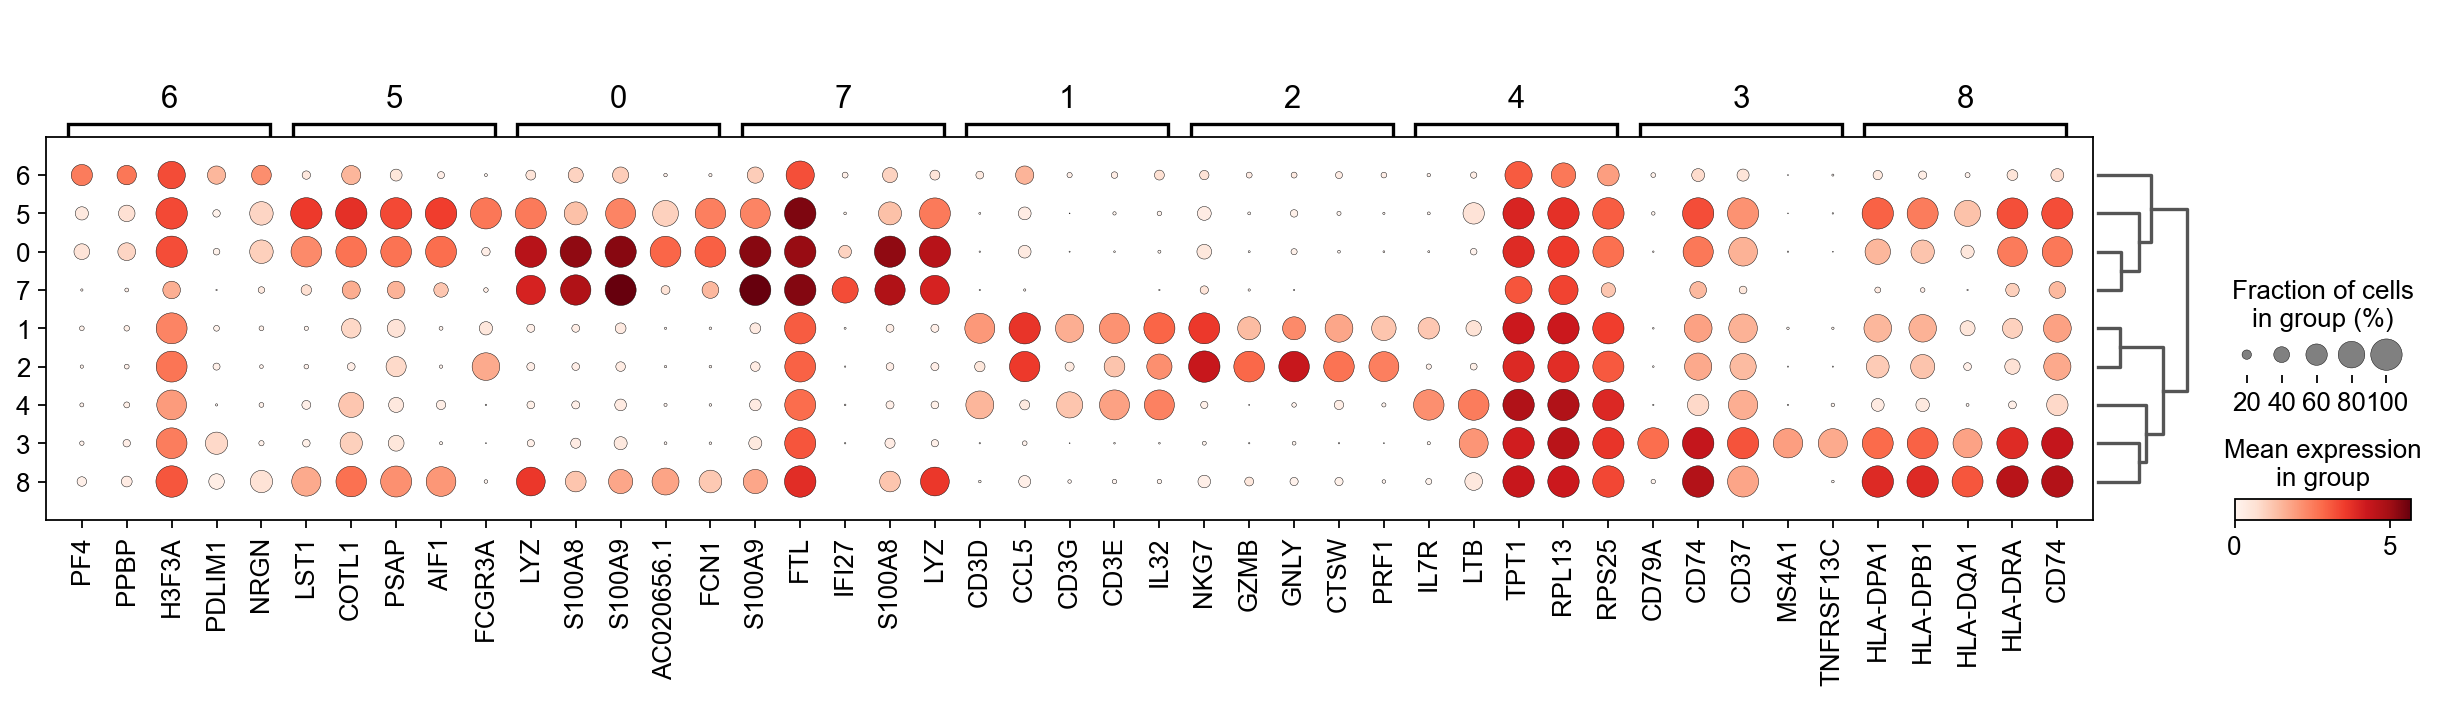

In [ ]:
sc.pl.rank_genes_groups_dotplot(adata, n_genes=5, key="wilcoxon", groupby="louvain_0.6")

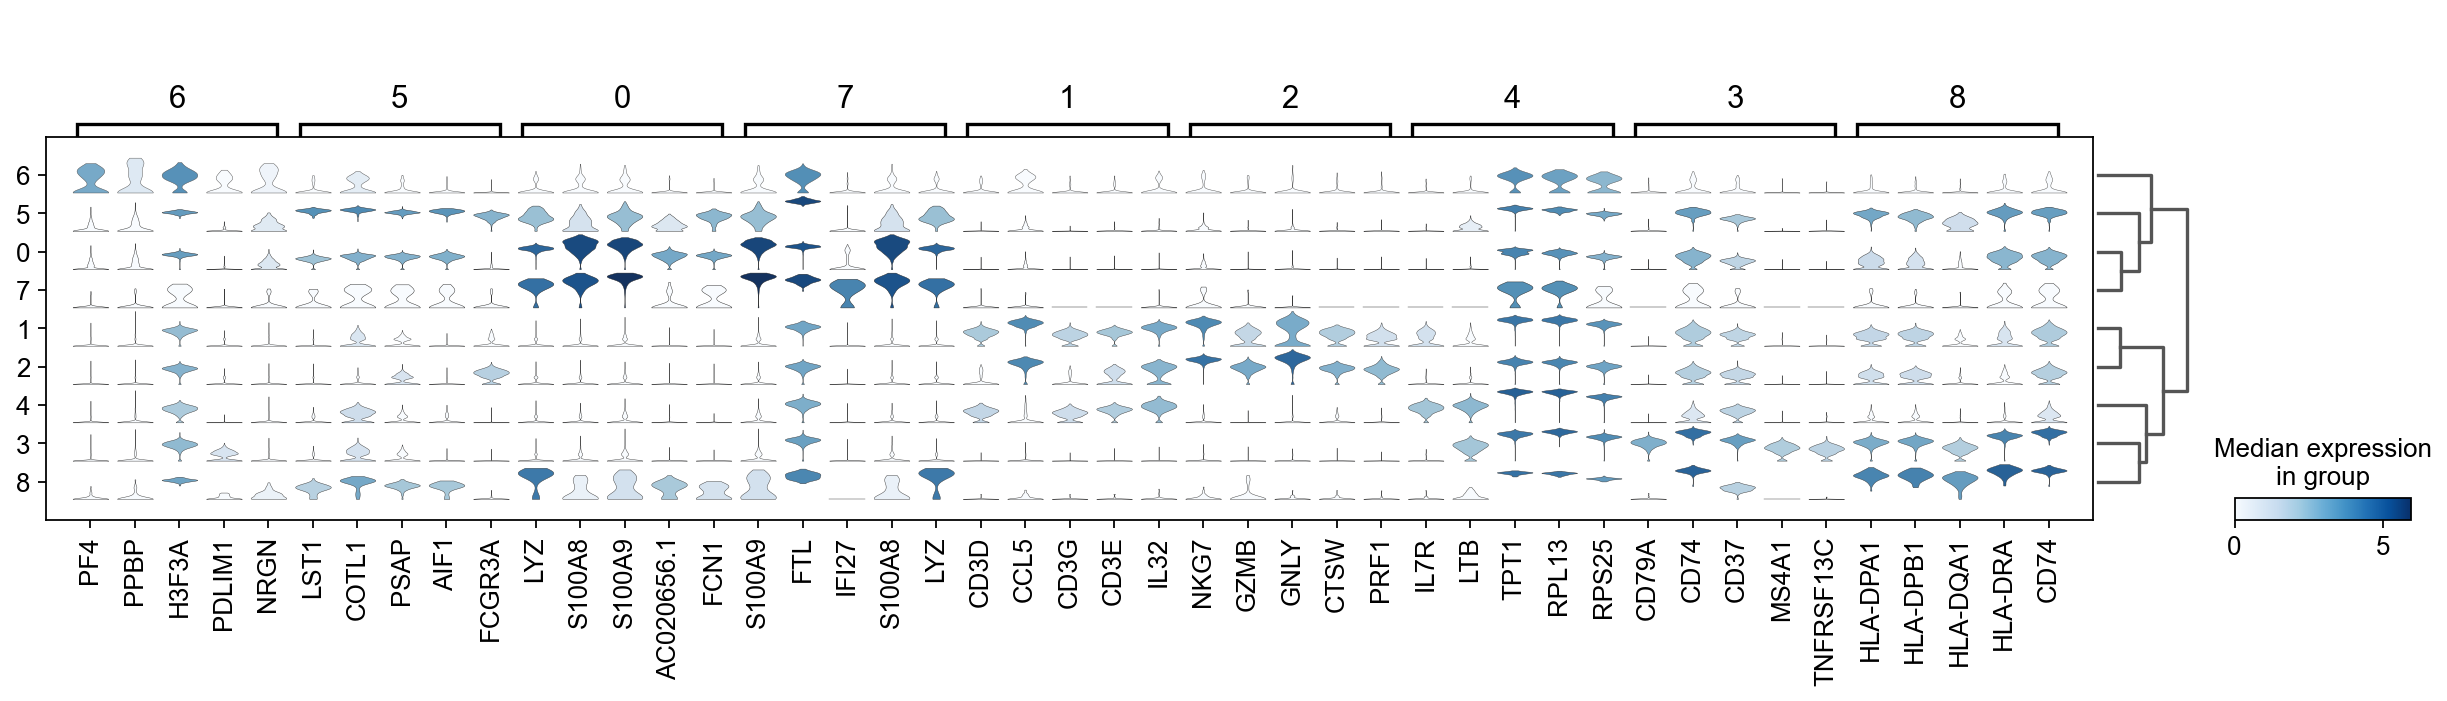

In [ ]:
sc.pl.rank_genes_groups_stacked_violin(adata, n_genes=5, key="wilcoxon", groupby="louvain_0.6")

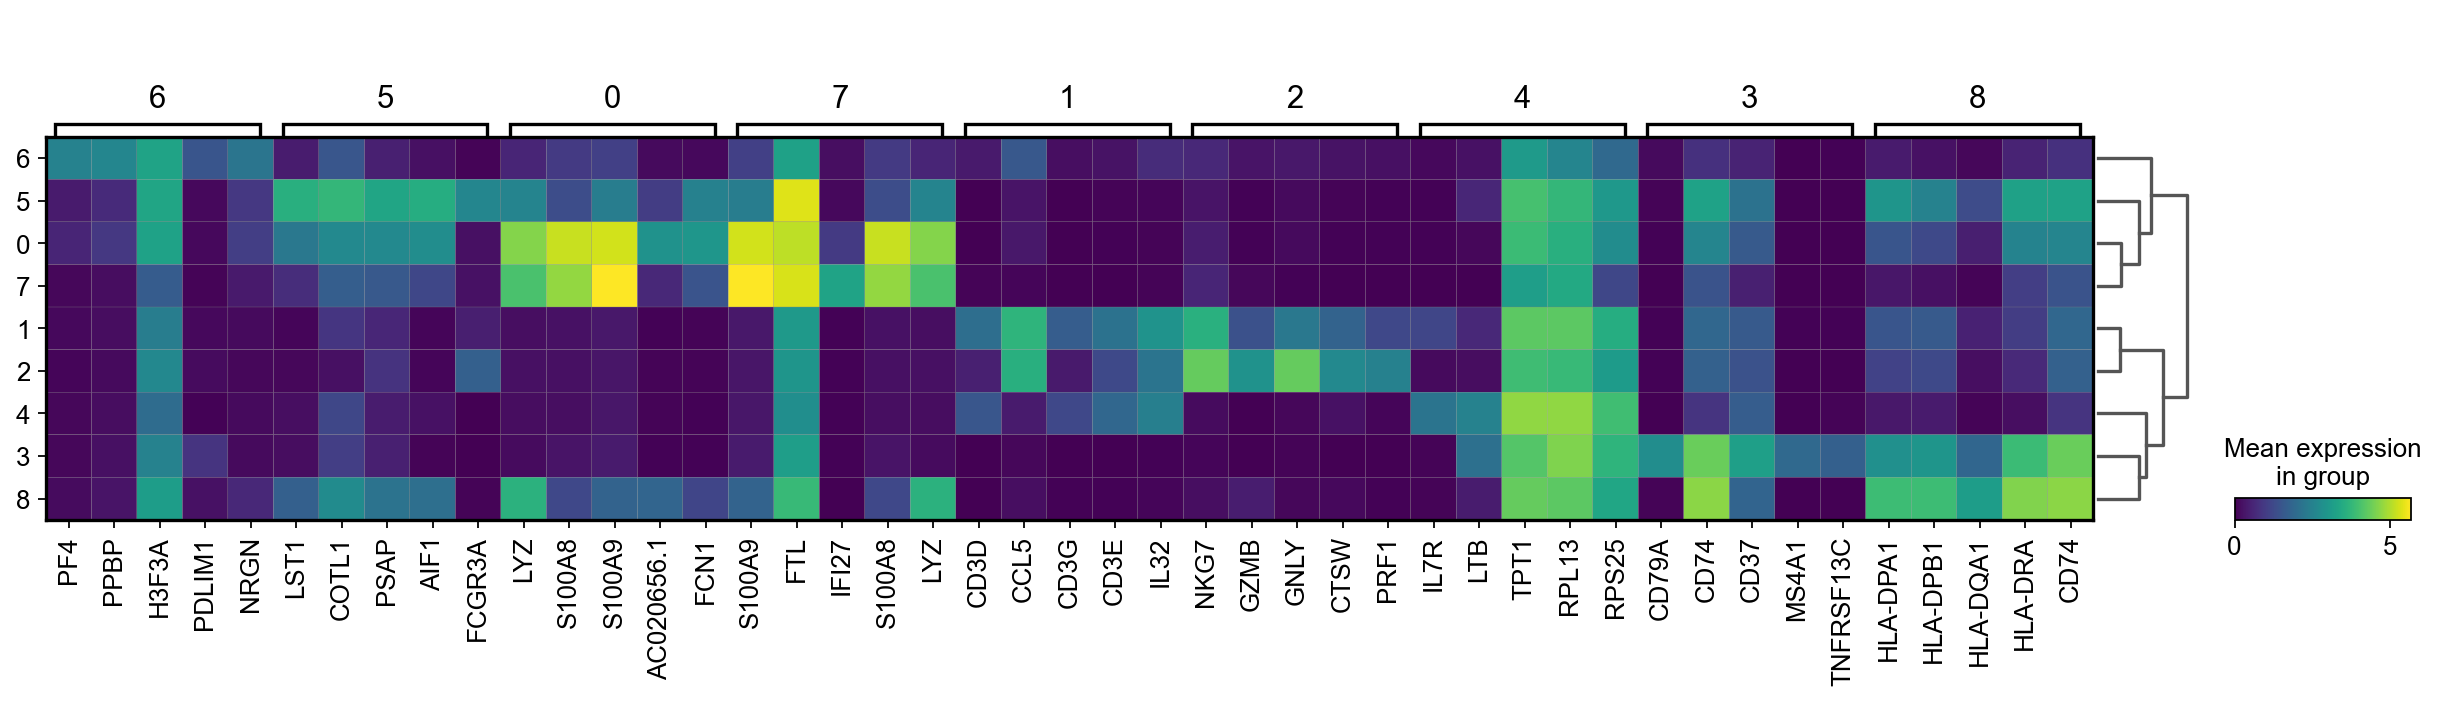

In [ ]:
sc.pl.rank_genes_groups_matrixplot(adata, n_genes=5, key="wilcoxon", groupby="louvain_0.6")

### Compare specific clusters

We can also do pairwise comparisons of individual clusters on one vs many clusters.

For instance, clusters 1 & 2 have very similar expression profiles.

ranking genes
    finished (0:00:02)


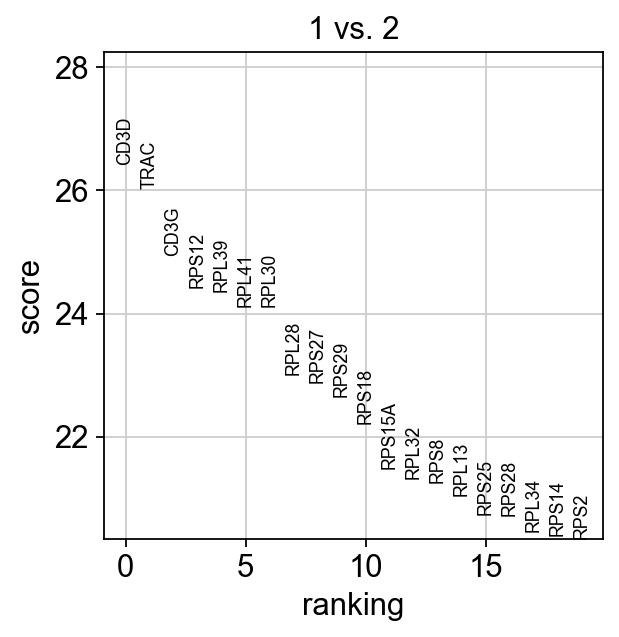

In [ ]:
sc.tl.rank_genes_groups(adata, 'louvain_0.6', groups=['1'], reference='2', method='wilcoxon')
sc.pl.rank_genes_groups(adata, groups=['1'], n_genes=20)

Plot as violins for those two groups.

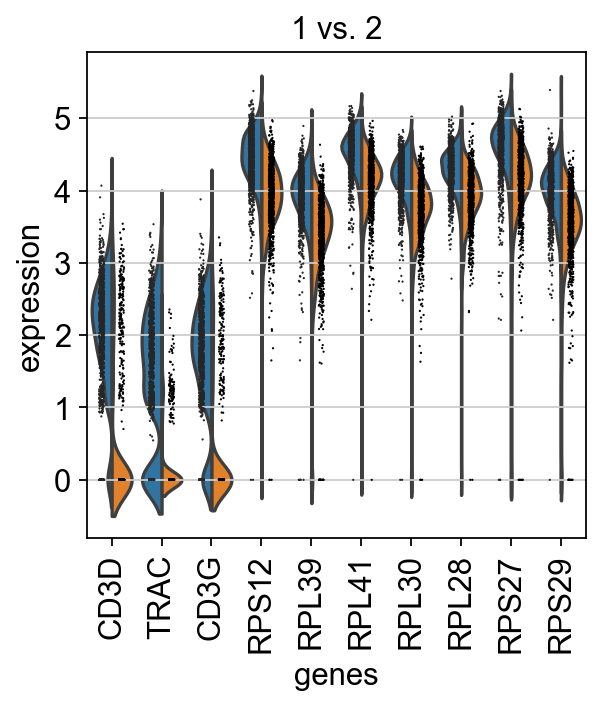

In [ ]:
sc.pl.rank_genes_groups_violin(adata, groups='1', n_genes=10)


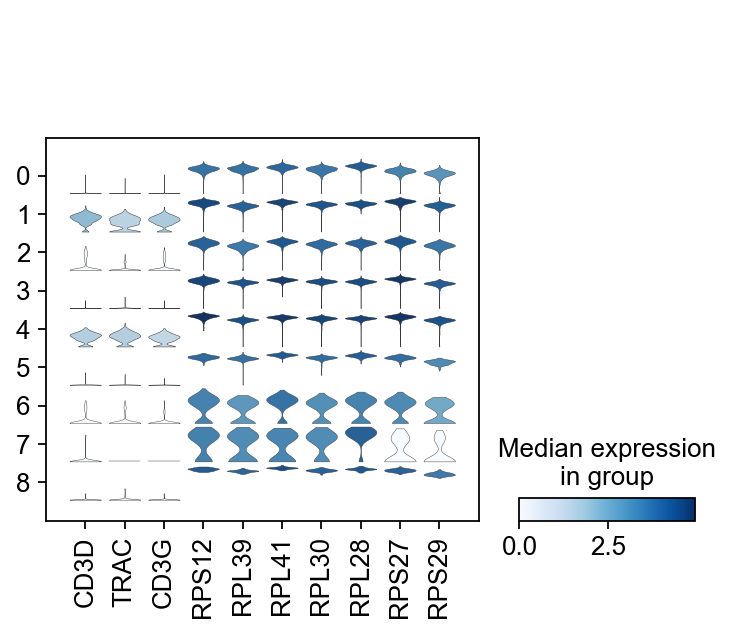

In [ ]:
# plot the same genes as violins across all the datasets.

# convert numpy.recarray to list
mynames = [x[0] for x in adata.uns['rank_genes_groups']['names'][:10]]
sc.pl.stacked_violin(adata, mynames, groupby = 'louvain_0.6')


## Differential expression across conditions
***

The second way of computing differential expression is to answer which genes are differentially expressed within a cluster. For example, in our case we have libraries comming from patients and controls and we would like to know which genes are influenced the most in a particular cell type.

For this end, we will first subset our data for the desired cell cluster, then change the cell identities to the variable of comparison (which now in our case is the "type", e.g. Covid/Ctrl).


In [ ]:
cl1 = adata[adata.obs['louvain_0.6'] == '1',:]
cl1.obs['type'].value_counts()

Ctrl     693
Covid    305
Name: type, dtype: int64

ranking genes


Trying to set attribute `._uns` of view, copying.


    finished (0:00:01)


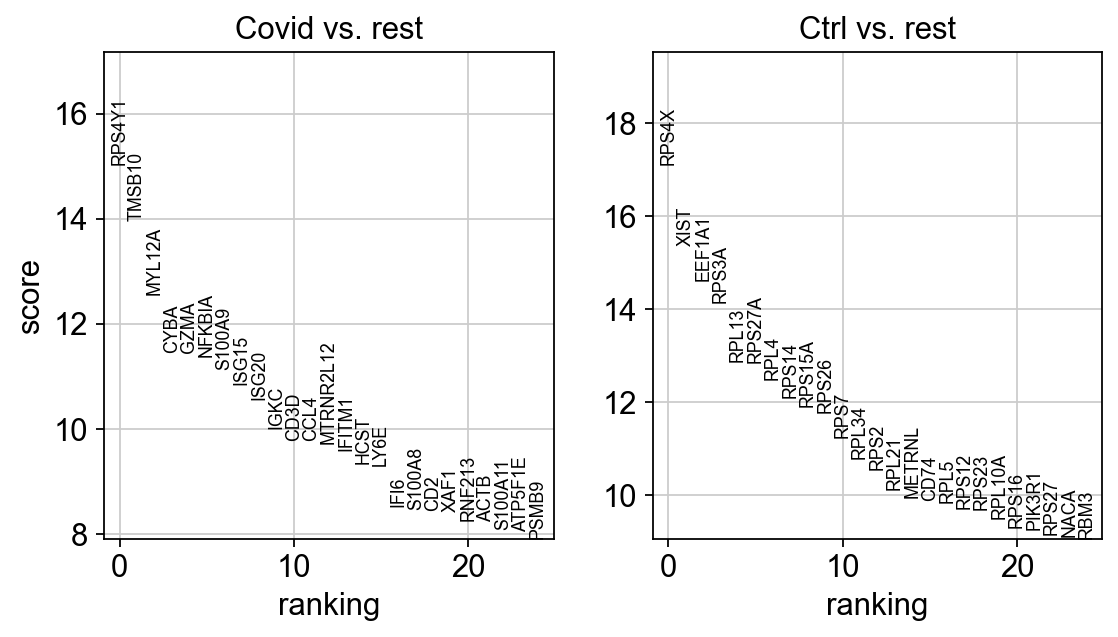

In [ ]:
sc.tl.rank_genes_groups(cl1, 'type', method='wilcoxon', key_added = "wilcoxon")
sc.pl.rank_genes_groups(cl1, n_genes=25, sharey=False, key="wilcoxon")

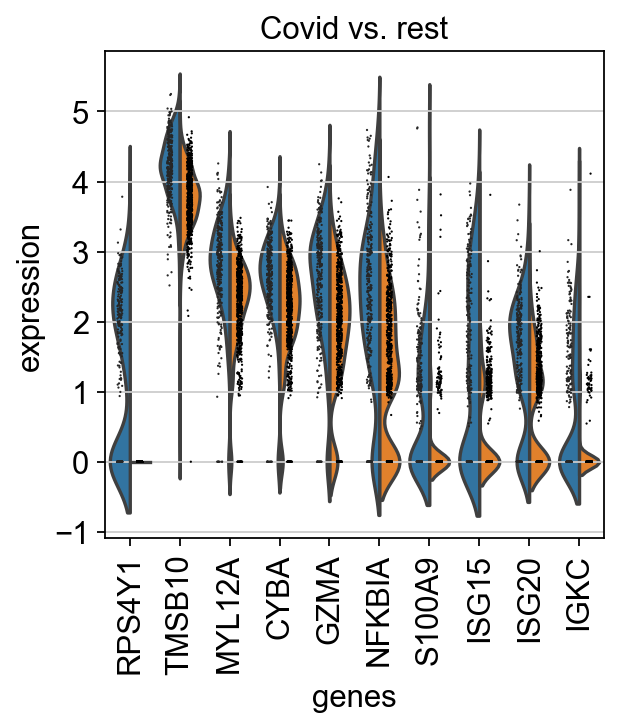

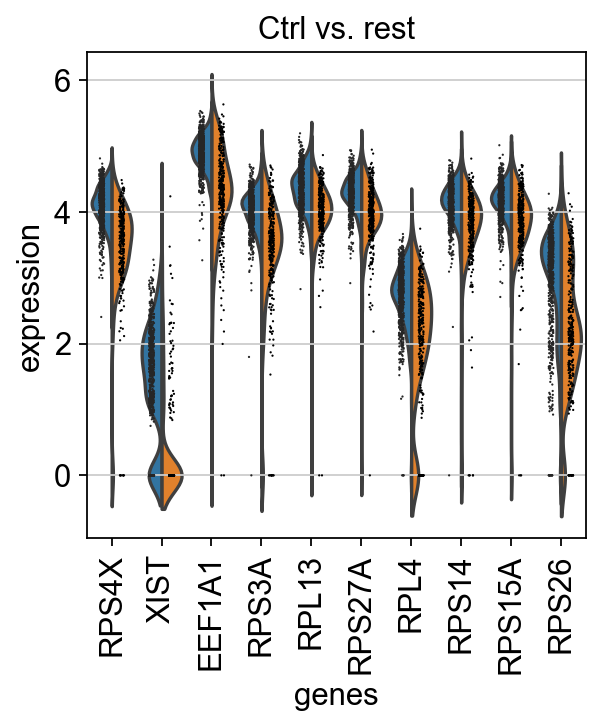

In [ ]:
sc.pl.rank_genes_groups_violin(cl1, n_genes=10, key="wilcoxon")


We can also plot these genes across all clusters, but split by "type", to check if the genes are also up/downregulated in other celltypes.


In [ ]:
import seaborn as sns

genes1 = sc.get.rank_genes_groups_df(cl1, group='Covid', key='wilcoxon')['names'][:5]
genes2 = sc.get.rank_genes_groups_df(cl1, group='Ctrl', key='wilcoxon')['names'][:5]
genes = genes1.tolist() +  genes2.tolist()
df = sc.get.obs_df(adata, genes + ['louvain_0.6','type'], use_raw=False)
df2 = df.melt(id_vars=["louvain_0.6",'type'], value_vars=genes)



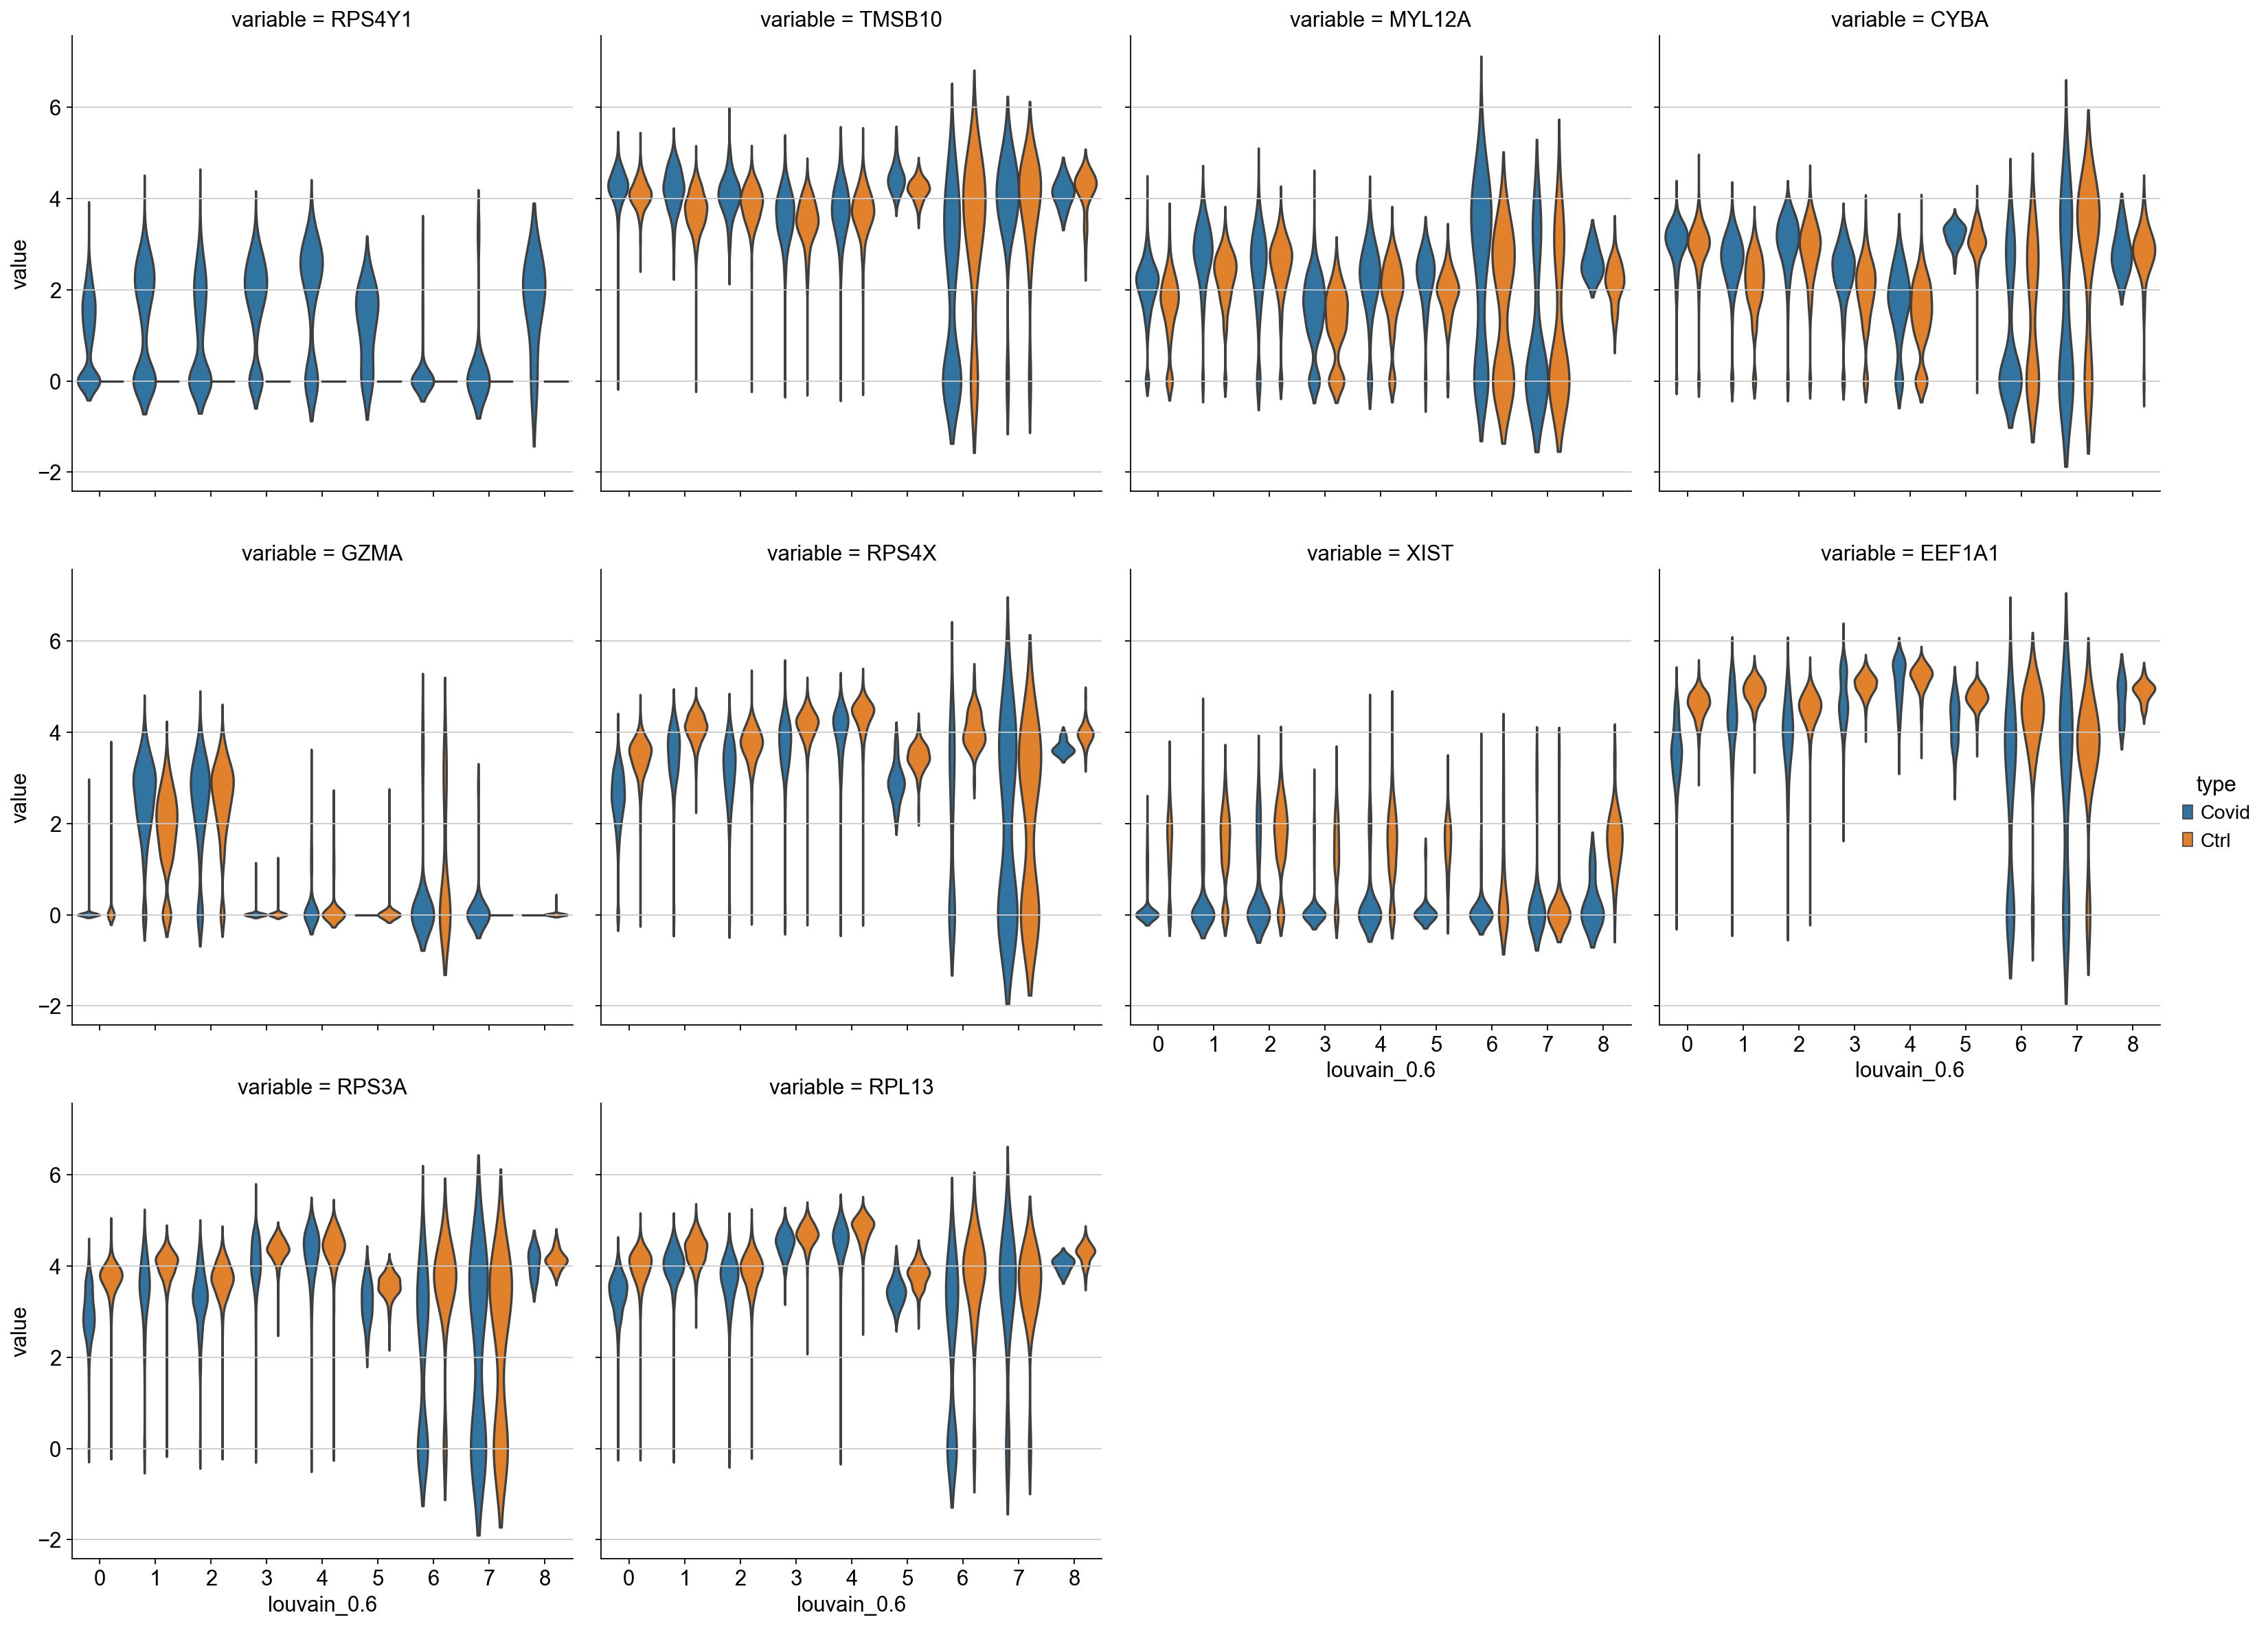

In [ ]:
sns.catplot(x = "louvain_0.6", y = "value", hue = "type", kind = 'violin',
               col = "variable", data = df2, col_wrap=4, inner=None)

## Gene Set Analysis
***

Hypergeometric enrichment test

Having a defined list of differentially expressed genes, you can now look for their combined function using hypergeometric test:


In [ ]:
#Available databases : ‘Human’, ‘Mouse’, ‘Yeast’, ‘Fly’, ‘Fish’, ‘Worm’
gene_set_names = gseapy.get_library_name(organism='Human')
print(gene_set_names)

['ARCHS4_Cell-lines', 'ARCHS4_IDG_Coexp', 'ARCHS4_Kinases_Coexp', 'ARCHS4_TFs_Coexp', 'ARCHS4_Tissues', 'Achilles_fitness_decrease', 'Achilles_fitness_increase', 'Aging_Perturbations_from_GEO_down', 'Aging_Perturbations_from_GEO_up', 'Allen_Brain_Atlas_10x_scRNA_2021', 'Allen_Brain_Atlas_down', 'Allen_Brain_Atlas_up', 'Azimuth_Cell_Types_2021', 'BioCarta_2013', 'BioCarta_2015', 'BioCarta_2016', 'BioPlanet_2019', 'BioPlex_2017', 'CCLE_Proteomics_2020', 'CORUM', 'COVID-19_Related_Gene_Sets', 'COVID-19_Related_Gene_Sets_2021', 'Cancer_Cell_Line_Encyclopedia', 'CellMarker_Augmented_2021', 'ChEA_2013', 'ChEA_2015', 'ChEA_2016', 'Chromosome_Location', 'Chromosome_Location_hg19', 'ClinVar_2019', 'DSigDB', 'Data_Acquisition_Method_Most_Popular_Genes', 'DepMap_WG_CRISPR_Screens_Broad_CellLines_2019', 'DepMap_WG_CRISPR_Screens_Sanger_CellLines_2019', 'Descartes_Cell_Types_and_Tissue_2021', 'DisGeNET', 'Disease_Perturbations_from_GEO_down', 'Disease_Perturbations_from_GEO_up', 'Disease_Signatures

Get the significant DEGs.

In [ ]:
#?gseapy.enrichr
glist = sc.get.rank_genes_groups_df(cl1, group='Covid',
                                    key='wilcoxon', log2fc_min=0.25,
                                    pval_cutoff=0.01)['names'].squeeze().str.strip().tolist()
print(len(glist))

164


In [ ]:
enr_res = gseapy.enrichr(gene_list=glist,
                     organism='Human',
                     gene_sets='GO_Biological_Process_2018',
                     description='pathway',
                     cutoff = 0.5)

In [ ]:
enr_res.results.head()

,Gene_set,Term,Overlap,P-value,Adjusted P-value,Old P-value,Old Adjusted P-value,Odds Ratio,Combined Score,Genes
0,GO_Biological_Process_2018,cellular response to type I interferon (GO:007...,15/65,3.862744e-18,2.559068e-15,0,0,39.837584,1597.294054,IFITM1;SP100;STAT1;MX1;IFI6;ISG15;IFI35;SAMHD1...
1,GO_Biological_Process_2018,type I interferon signaling pathway (GO:0060337),15/65,3.862744e-18,2.559068e-15,0,0,39.837584,1597.294054,IFITM1;SP100;STAT1;MX1;IFI6;ISG15;IFI35;SAMHD1...
2,GO_Biological_Process_2018,cytokine-mediated signaling pathway (GO:0019221),33/633,1.314537e-17,5.805873e-15,0,0,8.076183,313.924971,IFITM1;SP100;IFI6;IFI35;SAMHD1;PSMB10;IFIT3;PS...
3,GO_Biological_Process_2018,mitochondrial ATP synthesis coupled electron t...,10/85,1.923650e-09,6.372089e-07,0,0,17.109091,343.363058,COX7B;NDUFA12;NDUFA4;NDUFA3;NDUFB3;NDUFB2;UQCR...
4,GO_Biological_Process_2018,respiratory electron transport chain (GO:0022904),10/94,5.217930e-09,1.382752e-06,0,0,15.269017,291.197936,COX7B;NDUFA12;NDUFA4;NDUFA3;NDUFB3;NDUFB2;UQCR...



Some databases of interest:

* `GO_Biological_Process_2017b`
* `KEGG_2019_Human`
* `KEGG_2019_Mouse`
* `WikiPathways_2019_Human`
* `WikiPathways_2019_Mouse`

You visualize your results using a simple barplot, for example:


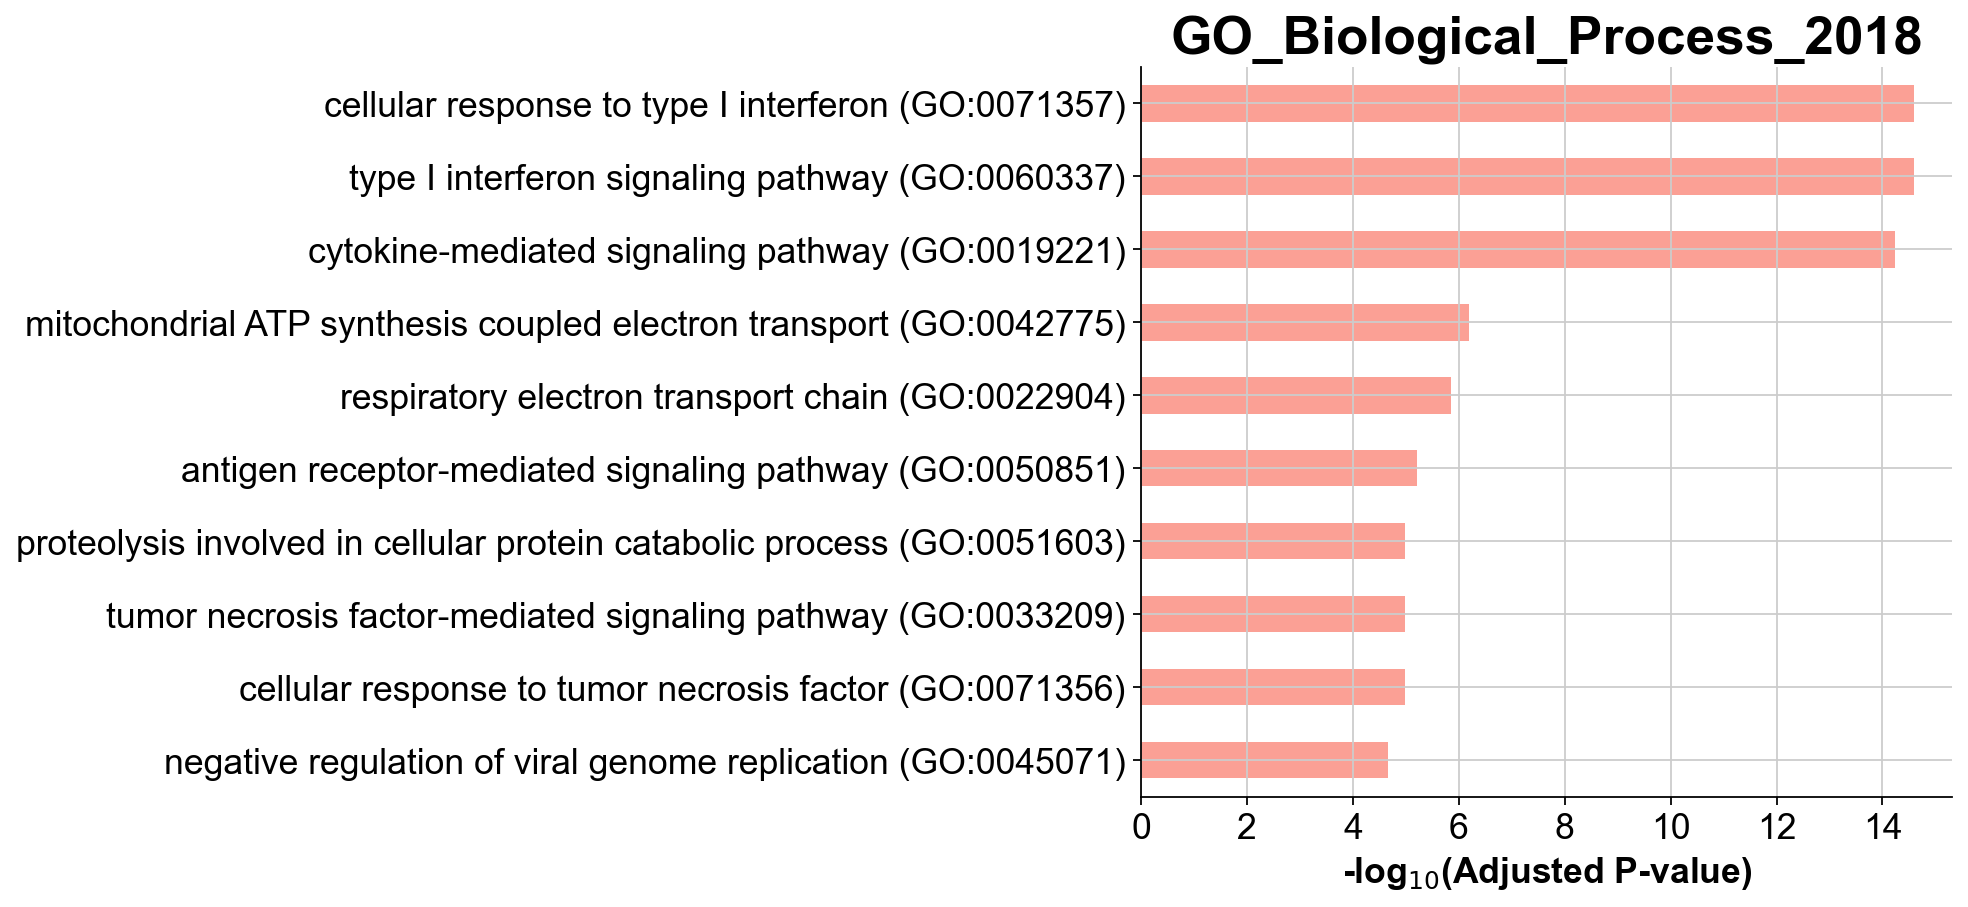

In [ ]:
gseapy.barplot(enr_res.res2d,title='GO_Biological_Process_2018')

## Gene Set Enrichment Analysis (GSEA)

Besides the enrichment using hypergeometric test, we can also perform gene set enrichment analysis (GSEA), which scores ranked genes list (usually based on fold changes) and computes permutation test to check if a particular gene set is more present in the Up-regulated genes, amongthe DOWN_regulated genes or not differentially regulated.


We need a table with all DEGs and their log foldchanges. However, many lowly expressed genes will have high foldchanges and just contribue noise, so also filter for expression in enough cells.

In [ ]:
gene_rank = sc.get.rank_genes_groups_df(cl1, group='Covid', key='wilcoxon')[['names','logfoldchanges']]
gene_rank.sort_values(by=['logfoldchanges'], inplace=True, ascending=False)

In [ ]:
# calculate_qc_metrics will calculate number of cells per gene
sc.pp.calculate_qc_metrics(cl1, percent_top=None, log1p=False, inplace=True)

# filter for genes expressed in at least 30 cells.
gene_rank = gene_rank[gene_rank['names'].isin(cl1.var_names[cl1.var.n_cells_by_counts>30])]


In [ ]:
gene_rank

,names,logfoldchanges
0,RPS4Y1,31.311884
36,DDX3Y,28.709471
90,EIF1AY,27.923817
166,TTTY15,27.691143
264,UTY,27.231516
...,...,...
18062,PHLDA1,-2.782725
18422,WHRN,-2.796236
18750,XIST,-2.828403
17578,CRIP2,-4.180913


 Once our list of genes are sorted, we can proceed with the enrichment itself. We can use the package to get gene set from the Molecular Signature Database (MSigDB) and select KEGG pathways as an example.


In [ ]:
#Available databases : ‘Human’, ‘Mouse’, ‘Yeast’, ‘Fly’, ‘Fish’, ‘Worm’
gene_set_names = gseapy.get_library_name(organism='Human')
print(gene_set_names)

['ARCHS4_Cell-lines', 'ARCHS4_IDG_Coexp', 'ARCHS4_Kinases_Coexp', 'ARCHS4_TFs_Coexp', 'ARCHS4_Tissues', 'Achilles_fitness_decrease', 'Achilles_fitness_increase', 'Aging_Perturbations_from_GEO_down', 'Aging_Perturbations_from_GEO_up', 'Allen_Brain_Atlas_10x_scRNA_2021', 'Allen_Brain_Atlas_down', 'Allen_Brain_Atlas_up', 'Azimuth_Cell_Types_2021', 'BioCarta_2013', 'BioCarta_2015', 'BioCarta_2016', 'BioPlanet_2019', 'BioPlex_2017', 'CCLE_Proteomics_2020', 'CORUM', 'COVID-19_Related_Gene_Sets', 'COVID-19_Related_Gene_Sets_2021', 'Cancer_Cell_Line_Encyclopedia', 'CellMarker_Augmented_2021', 'ChEA_2013', 'ChEA_2015', 'ChEA_2016', 'Chromosome_Location', 'Chromosome_Location_hg19', 'ClinVar_2019', 'DSigDB', 'Data_Acquisition_Method_Most_Popular_Genes', 'DepMap_WG_CRISPR_Screens_Broad_CellLines_2019', 'DepMap_WG_CRISPR_Screens_Sanger_CellLines_2019', 'Descartes_Cell_Types_and_Tissue_2021', 'DisGeNET', 'Disease_Perturbations_from_GEO_down', 'Disease_Perturbations_from_GEO_up', 'Disease_Signatures

 Next, we will be using the GSEA. This will result in a table containing information for several pathways. We can then sort and filter those pathways to visualize only the top ones. You can select/filter them by either `p-value` or normalized enrichemnet score (`NES`).


In [ ]:
res = gseapy.prerank(rnk=gene_rank, gene_sets='KEGG_2021_Human')

In [ ]:
terms = res.res2d.index
terms[:20]

Index(['Viral protein interaction with cytokine and cytokine receptor',
       'Epstein-Barr virus infection', 'Amoebiasis',
       'JAK-STAT signaling pathway', 'Necroptosis', 'Rheumatoid arthritis',
       'Leukocyte transendothelial migration', 'Fatty acid degradation',
       'Drug metabolism', 'RNA transport',
       'Epithelial cell signaling in Helicobacter pylori infection',
       'Legionellosis', 'Pertussis', 'Toxoplasmosis', 'Mineral absorption',
       'Proteasome', 'Prion disease',
       'Neuroactive ligand-receptor interaction', 'Apoptosis',
       'Pentose phosphate pathway'],
      dtype='object', name='Term')

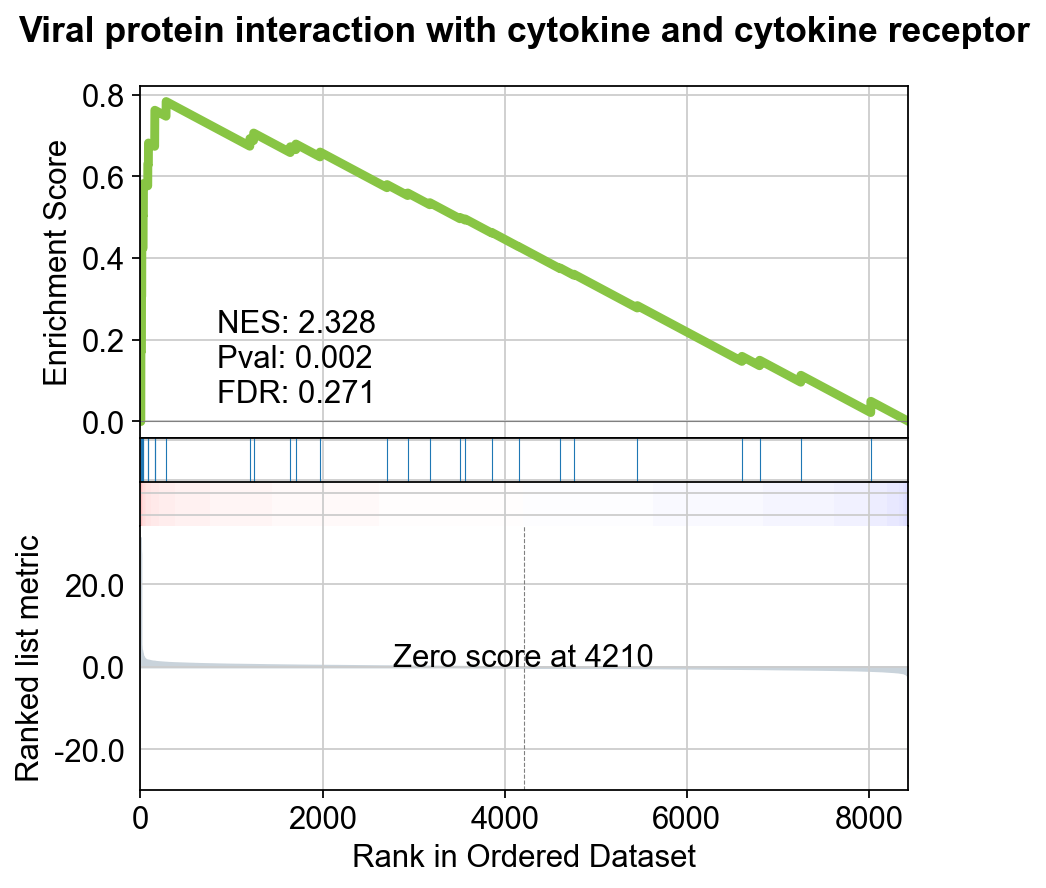

In [ ]:
gseapy.gseaplot(rank_metric=res.ranking, term=terms[0], **res.results[terms[0]])

<style>
div.blue { background-color:#e6f0ff; border-radius: 5px; padding: 10px;}
</style>
<div class = "blue">
**Your turn**

Which KEGG pathways are upregulated in this cluster?
Which KEGG pathways are dowregulated in this cluster?
Change the pathway source to another gene set (e.g. "CP:WIKIPATHWAYS" or "CP:REACTOME" or "CP:BIOCARTA" or "GO:BP") and check the if you get simmilar results?
</div>

Finally, lets save the integrated data for further analysis.


In [ ]:
adata.write_h5ad('./data/results/scanpy_DGE_covid.h5ad')